# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение (продвинутый уровень)

**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации

**Датасет:** *House Prices — Advanced Regression Techniques* (Kaggle)

**Выполнил:** Боттер Вадим Валерьевич

**Группа:** ПКТб-23-1

**Преподаватель:** *Спирин Игорь Сергеевич*

**Ссылка на репозиторий:** https://github.com/uat0/ml-course-botter

**Путь к модулю:** `module-2-house-prices/notebook.ipynb`

**Дата сдачи:** 2026-10-09

## Введение

**Задача:** регрессия — по 79 характеристикам дома (площадь, качество отделки, район, год постройки, гараж и т.д.) предсказать **цену продажи `SalePrice`** — непрерывную величину в долларах (от \$34 900 до \$755 000).

**ML-проект для регрессии** — это цепочка этапов, где каждый следующий опирается на предыдущий: *сбор данных → разведочный анализ (EDA) → предобработка (пропуски, выбросы, кодирование) → создание признаков → обучение и подбор гиперпараметров → оценка на отложенной выборке → интерпретация → сохранение и использование модели*. Ошибка на ранних этапах (например, неправильно заполненные пропуски) «протекает» во все следующие.

**Почему регрессия, а не классификация.** В классификации ответ — метка из конечного набора («выжил / не выжил», как в Модуле 1). Здесь ответ — число на непрерывной шкале: дом может стоить \$163 000 или \$163 500, и ошибка на \$500 гораздо лучше ошибки на \$50 000. Поэтому модель должна выдавать число, а качество измеряется *величиной* ошибки, а не долей угаданных классов.

**Какая метрика важнее.**
- **RMSE** — главная: она сильнее штрафует крупные промахи (ошибиться на \$100k у дорогого дома — дорого для покупателя/банка). Считаем её на **лог-шкале** — так она отражает *относительную* ошибку, и одинаково важна точность и для дешёвых, и для дорогих домов (так же оценивает Kaggle).
- **MAE** — понятная бизнесу «средняя ошибка в долларах», менее чувствительна к выбросам.
- **R²** — доля объяснённой дисперсии, удобна для сравнения с другими работами, но сама по себе не говорит, сколько долларов мы ошибаемся.

**Цели работы:**
1. Провести полный EDA датасета House Prices и обоснованно обработать пропуски, выбросы и скошенность.
2. Обучить 4+ модели (Linear Regression, Ridge, Lasso, ElasticNet + бонусные XGBoost/LightGBM/Stacking) и достичь **R² ≥ 0.90** на отложенной выборке.
3. Реализовать функцию `predict_price()` для оценки нового дома и выложить модели в репозиторий так, чтобы их можно было загрузить без переобучения.

## Теоретическая часть

### 1. Регрессия
Регрессия — это задача обучения с учителем, в которой модель учится отображать признаки объекта в **число**. Линейная регрессия ищет веса $w$, при которых $\hat y = w_0 + w_1x_1 + \dots + w_px_p$ даёт минимальную сумму квадратов ошибок. В отличие от классификации, где важно, *по какую сторону* границы попал объект, в регрессии важно, *насколько далеко* предсказание от правды. Примеры: цена квартиры, спрос на товар завтра, время доставки, зарплата по резюме. Линейная модель хороша тем, что её веса можно прочитать как «на сколько изменится цена при изменении признака на единицу».

### 2. Пропуски (NaN)
Пропуски появляются, когда значение не собрали, не применимо или потерялось при выгрузке. Различают три механизма: **MCAR** — пропуск полностью случаен (сбой записи); **MAR** — зависит от других *наблюдаемых* признаков (`LotFrontage` чаще пропущен в определённых районах); **MNAR** — зависит от самого значения. В House Prices большинство пропусков — особый случай: *NaN означает «объекта нет»* (`PoolQC` = NaN → нет бассейна), это не потеря данных, а информация. Поэтому стратегии разные: смысловые пропуски → категория `"None"`/0, случайные → медиана по похожей группе (району), единичные → мода/медиана. Удалять строки здесь нельзя — потеряем почти все дома (у 99.5% нет бассейна).

### 3. Регуляризация
Когда признаков много (у нас ~250 после One-Hot) и они коррелируют между собой, обычная регрессия подгоняет огромные веса разного знака, которые компенсируют друг друга, — модель переобучается. Регуляризация добавляет к ошибке штраф за размер весов:

$$\text{Ridge (L2)}: \; \min_w \sum (y_i-\hat y_i)^2 + \alpha\sum w_j^2 \qquad \text{Lasso (L1)}: \; \min_w \sum (y_i-\hat y_i)^2 + \alpha\sum |w_j|$$

**Ridge** равномерно «сжимает» все веса, но не обнуляет их — хорош при мультиколлинеарности (вес делится между похожими признаками). **Lasso** может сделать веса ровно нулевыми, т.е. сам отбирает признаки. **ElasticNet** смешивает оба штрафа (параметр `l1_ratio`), сохраняя отбор признаков и устойчивость к коррелированным группам. Сила штрафа $\alpha$ подбирается кросс-валидацией.

### 4. Логарифмирование целевой
Цены домов скошены вправо: много домов по \$120–200k и длинный хвост дорогих. Линейная модель с квадратичной ошибкой тогда «тянется» за редкими дорогими домами, а остатки получаются неравномерными. Преобразование $y' = \ln(1+y)$ (`np.log1p`) сжимает хвост и делает распределение почти нормальным; заодно модель начинает предсказывать *процентные* изменения цены, что естественно для недвижимости. После предсказания возвращаемся в доллары через `np.expm1`.

### 5. Feature Engineering
Модель видит только то, что ей дали. Покупатель думает об «общей площади дома», а в данных она разбита на подвал, 1-й и 2-й этаж — сумма `TotalSF` оказывается сильнее каждого слагаемого. Аналогично «возраст дома на момент продажи» понятнее, чем два года по отдельности, а флаг `HasPool` отделяет «есть/нет» от площади. Взаимодействие `OverallQual × TotalSF` позволяет линейной модели учесть, что метр в качественном доме дороже.

### 6. Метрики регрессии
**MSE** — средний квадрат ошибки: сильно штрафует большие промахи, но измеряется в «долларах в квадрате». **RMSE** — корень из MSE, возвращает ошибку в исходные единицы. **MAE** — средняя абсолютная ошибка: интерпретируется проще всего и менее чувствительна к выбросам. **R²** показывает, какую долю разброса цен объяснила модель: 1 — идеально, 0 — не лучше, чем всегда предсказывать среднее, < 0 — хуже среднего. RMSE ≥ MAE всегда; большой разрыв между ними говорит о наличии крупных ошибок.

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE} \quad\quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

**Кросс-валидация (k-fold):** обучающая выборка делится на $k$ частей; модель $k$ раз учится на $k-1$ частях и проверяется на оставшейся. Среднее по фолдам — более надёжная оценка, чем одно случайное разбиение; именно по ней `GridSearchCV` выбирает $\alpha$.

### Сводная таблица моделей

| Модель | Штраф | Обнуляет признаки? | Когда использовать |
|---|---|---|---|
| Linear Regression | нет | нет | базовая линия, мало признаков |
| Ridge | $\alpha\sum w_j^2$ (L2) | нет | много коррелированных признаков |
| Lasso | $\alpha\sum \lvert w_j\rvert$ (L1) | **да** | нужен отбор признаков |
| ElasticNet | L1 + L2 | да | группы коррелированных признаков |

### Схема пайплайна этой работы
```
train.csv ─► EDA ─► выбросы ─► пропуски ─► log1p(SalePrice) ─► Feature Engineering
          ─► Label/One-Hot ─► log1p скошенных признаков ─► train/test split ─► StandardScaler
          ─► LR / Ridge / Lasso / ElasticNet (+XGB, LGBM, Stacking) ─► метрики ─► predict_price() ─► .pkl
```

## Описание данных

Сначала подключаем библиотеки и загружаем данные.

In [1]:
# ===== Импорт библиотек и общие настройки =====
import os, json, time, warnings                # работа с файлами, JSON, временем
warnings.filterwarnings('ignore')              # скрываем технические предупреждения библиотек

import numpy as np                             # численные вычисления
import pandas as pd                            # табличные данные
import matplotlib.pyplot as plt                # графики
import seaborn as sns                          # статистическая визуализация
from scipy import stats                        # Q-Q plot и статистика

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler                  # масштабирование
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib                                   # сохранение моделей в .pkl

RANDOM_STATE = 42                               # фиксируем случайность для воспроизводимости
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')                # единый стиль графиков
plt.rcParams['figure.dpi'] = 100

# Папки для артефактов (пути относительные — внутри module-2-house-prices/)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)
print('✅ Библиотеки загружены, pandas', pd.__version__)

✅ Библиотеки загружены, pandas 3.0.5


In [2]:
# ===== Загрузка датасета =====
train_df = pd.read_csv('data/train.csv')   # обучающая выборка (есть SalePrice)
test_df = pd.read_csv('data/test.csv')     # тестовая выборка Kaggle (без SalePrice)

print(train_df.shape, test_df.shape)        # обязательный вывод размерностей

(1460, 81) (1459, 80)


In [3]:
# ===== Структура датасета =====
feature_raw = [c for c in train_df.columns if c not in ['Id', 'SalePrice']]  # 79 исходных признаков
num_cols_raw = train_df[feature_raw].select_dtypes(include='number').columns   # числовые
cat_cols_raw = train_df[feature_raw].select_dtypes(exclude='number').columns   # строковые (категориальные)

print(f'Признаков всего:        {len(feature_raw)}')
print(f'Числовых признаков:     {len(num_cols_raw)}')
print(f'Категориальных:         {len(cat_cols_raw)}')
print(f'Столбцов с пропусками:  {(train_df.isnull().sum() > 0).sum()}')

# Таблица по ключевым столбцам: тип и доля пропусков
key_cols = ['Id', 'SalePrice', 'OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearBuilt',
            'GarageCars', 'Neighborhood', 'LotFrontage', 'PoolQC']
key_info = pd.DataFrame({
    'Тип': train_df[key_cols].dtypes.astype(str),
    'Пропуски, %': (train_df[key_cols].isnull().mean() * 100).round(1),
    'Уникальных': train_df[key_cols].nunique()
})
key_info

Признаков всего:        79
Числовых признаков:     36
Категориальных:         43
Столбцов с пропусками:  19


,Тип,"Пропуски, %",Уникальных
Id,int64,0.0,1460
SalePrice,int64,0.0,663
OverallQual,int64,0.0,10
GrLivArea,int64,0.0,861
TotalBsmtSF,int64,0.0,721
YearBuilt,int64,0.0,112
GarageCars,int64,0.0,5
Neighborhood,str,0.0,25
LotFrontage,float64,17.7,110
PoolQC,str,99.5,3


In [4]:
# ===== Распределение целевой переменной SalePrice =====
y_raw = train_df['SalePrice']                       # цена в долларах
target_stats = {
    'mean': y_raw.mean(), 'median': y_raw.median(),
    'min': y_raw.min(), 'max': y_raw.max(),
    'skew': y_raw.skew(), 'kurtosis': y_raw.kurtosis()
}
print(f"Среднее:   ${target_stats['mean']:,.0f}")
print(f"Медиана:   ${target_stats['median']:,.0f}")
print(f"Диапазон:  ${target_stats['min']:,.0f} – ${target_stats['max']:,.0f}")
print(f"Skew:      {target_stats['skew']:.2f}  (> 0 → правый хвост)")
print(f"Kurtosis:  {target_stats['kurtosis']:.2f}")

Среднее:   $180,921
Медиана:   $163,000
Диапазон:  $34,900 – $755,000
Skew:      1.88  (> 0 → правый хвост)
Kurtosis:  6.54


**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques (Ames Housing Dataset, Dean De Cock, 2011: продажи жилья в г. Эймс, штат Айова, 2006–2010).

**Структура:**
- Всего примеров в train: **1460**, в test: **1459**
- Признаков: **79** (+ `Id` + целевая `SalePrice`)
- Числовых признаков: **36**, категориальных (строковых): **43**
- Столбцов с пропусками в train: **19**

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Id | int64 | ID дома | 0% |
| SalePrice | int64 | **Целевая**: цена продажи, \$ | 0% |
| OverallQual | int64 (1–10) | Общее качество материалов и отделки | 0% |
| GrLivArea | int64 | Жилая площадь над землёй, кв. футы | 0% |
| TotalBsmtSF | int64 | Площадь подвала, кв. футы | 0% |
| YearBuilt | int64 | Год постройки | 0% |
| GarageCars | int64 | Вместимость гаража (машин) | 0% |
| Neighborhood | str | Район (25 значений) | 0% |
| LotFrontage | float64 | Ширина участка вдоль улицы, футы | 17.7% |
| PoolQC | str | Качество бассейна (NaN = нет бассейна) | 99.5% |

**Распределение целевой:**
- Среднее: **\$180 921**, медиана: **\$163 000** (среднее > медианы → правый хвост)
- Асимметрия (skew): **1.88** — сильное **правое смещение** → нужно логарифмирование
- Эксцесс: **6.54** — «тяжёлые хвосты», много дорогих домов-выбросов

**Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md` (создаётся ячейкой ниже).

In [5]:
# ===== Создаём файл описания датасета data/house_prices_info.md =====
info_text = f"""# House Prices — Advanced Regression Techniques

**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques
**Происхождение:** Ames Housing Dataset (Dean De Cock, 2011) — продажи жилья в г. Эймс (Айова, США), 2006–2010 гг.

## Структура
- train.csv: {train_df.shape[0]} строк × {train_df.shape[1]} столбцов (с целевой `SalePrice`)
- test.csv: {test_df.shape[0]} строк × {test_df.shape[1]} столбцов (без целевой)
- Признаков: {len(feature_raw)} (числовых: {len(num_cols_raw)}, категориальных: {len(cat_cols_raw)})
- Столбцов с пропусками в train: {(train_df.isnull().sum() > 0).sum()}

## Целевая переменная SalePrice
- Среднее: ${target_stats['mean']:,.0f}; медиана: ${target_stats['median']:,.0f}
- Диапазон: ${target_stats['min']:,.0f} – ${target_stats['max']:,.0f}
- Асимметрия: {target_stats['skew']:.2f} (правое смещение) → используем log1p
- Эксцесс: {target_stats['kurtosis']:.2f}

## Ключевые признаки
| Столбец | Описание |
|---|---|
| OverallQual | Общее качество материалов и отделки (1–10) |
| GrLivArea | Жилая площадь над землёй, кв. футы |
| TotalBsmtSF | Площадь подвала, кв. футы |
| GarageCars | Вместимость гаража (машин) |
| YearBuilt / YearRemodAdd | Год постройки / реконструкции |
| Neighborhood | Район города (25 значений) |
| PoolQC, Alley, Fence, MiscFeature | Пропуск = объекта нет |
"""
with open('data/house_prices_info.md', 'w', encoding='utf-8') as f:   # сохраняем рядом с данными
    f.write(info_text)
print('✅ data/house_prices_info.md создан')

✅ data/house_prices_info.md создан


## Подготовка данных и EDA

### 5.1 Первичный осмотр

In [6]:
# ===== Первичный осмотр =====
display(train_df.head())                              # первые 5 строк
train_df.info(verbose=False, memory_usage='deep')     # краткая сводка: типы и память

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 81 entries, Id to SalePrice
dtypes: float64(3), int64(35), str(43)
memory usage: 3.4 MB


In [7]:
# Описательная статистика по ключевым числовым признакам
train_df[['SalePrice', 'OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
          'YearBuilt', 'LotArea', 'LotFrontage']].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.2,79442.5,34900.0,129975.0,163000.0,214000.0,755000.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
GrLivArea,1460.0,1515.5,525.5,334.0,1129.5,1464.0,1776.8,5642.0
TotalBsmtSF,1460.0,1057.4,438.7,0.0,795.8,991.5,1298.2,6110.0
GarageCars,1460.0,1.8,0.7,0.0,1.0,2.0,2.0,4.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
LotFrontage,1201.0,70.0,24.3,21.0,59.0,69.0,80.0,313.0


Видно, что `LotArea` (площадь участка) и `TotalBsmtSF` имеют максимумы, во много раз превышающие 75-й перцентиль, — признаки скошены. `LotFrontage` заполнен только у 1201 дома из 1460.

### 5.2 Анализ пропусков

In [8]:
# ===== Анализ пропусков =====
missing = train_df.isnull().sum()                          # число NaN по столбцам
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(train_df) * 100).round(2)     # доля в процентах
missing_table = pd.DataFrame({'Пропусков': missing, '%': missing_pct})
print(f'Столбцов с пропусками: {len(missing_table)}')
missing_table

Столбцов с пропусками: 19


,Пропусков,%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


### 5.3 Визуализация (6 графиков + heatmap + Q-Q plot)

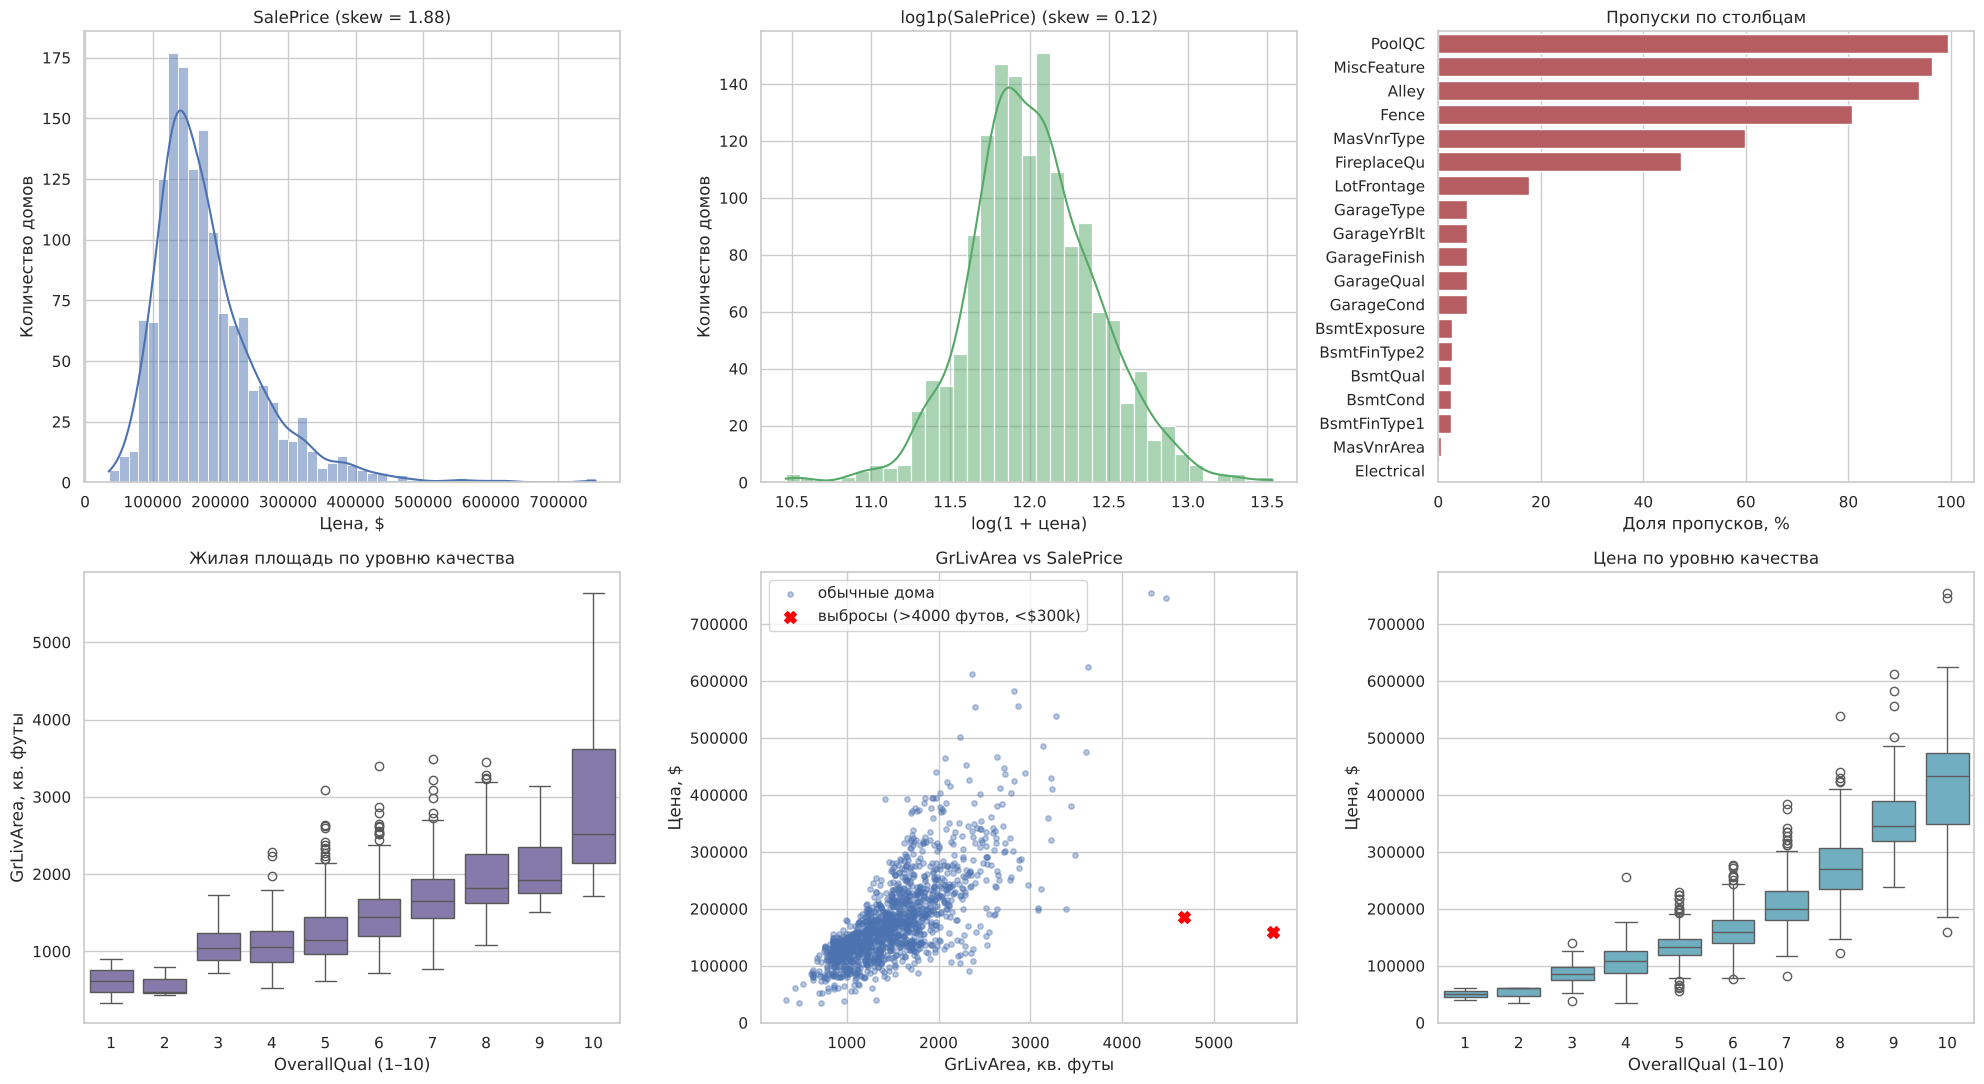

In [9]:
# ===== EDA: сетка из 6 графиков (сохраняется в examples/eda_plots.png) =====
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])   # лог-цена для сравнения

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1) Гистограмма SalePrice до логарифмирования
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0, 0], color='#4C72B0')
axes[0, 0].set(title=f"SalePrice (skew = {train_df['SalePrice'].skew():.2f})",
               xlabel='Цена, $', ylabel='Количество домов')

# 2) Гистограмма после log1p
sns.histplot(train_df['SalePrice_log'], kde=True, ax=axes[0, 1], color='#55A868')
axes[0, 1].set(title=f"log1p(SalePrice) (skew = {train_df['SalePrice_log'].skew():.2f})",
               xlabel='log(1 + цена)', ylabel='Количество домов')

# 3) Barplot пропусков (доля, %)
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=axes[0, 2], color='#C44E52')
axes[0, 2].set(title='Пропуски по столбцам', xlabel='Доля пропусков, %', ylabel='')

# 4) Boxplot: GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], color='#8172B2')
axes[1, 0].set(title='Жилая площадь по уровню качества', xlabel='OverallQual (1–10)',
               ylabel='GrLivArea, кв. футы')

# 5) Scatter: GrLivArea vs SalePrice — поиск выбросов
out_mask = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
axes[1, 1].scatter(train_df.loc[~out_mask, 'GrLivArea'], train_df.loc[~out_mask, 'SalePrice'],
                   alpha=0.4, s=15, label='обычные дома')
axes[1, 1].scatter(train_df.loc[out_mask, 'GrLivArea'], train_df.loc[out_mask, 'SalePrice'],
                   color='red', s=70, marker='X', label='выбросы (>4000 футов, <$300k)')
axes[1, 1].set(title='GrLivArea vs SalePrice', xlabel='GrLivArea, кв. футы', ylabel='Цена, $')
axes[1, 1].legend()

# 6) Boxplot: SalePrice по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='SalePrice', ax=axes[1, 2], color='#64B5CD')
axes[1, 2].set(title='Цена по уровню качества', xlabel='OverallQual (1–10)', ylabel='Цена, $')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110, bbox_inches='tight')   # артефакт для репозитория
plt.show()

**Наблюдения по графикам:**
1. **SalePrice** имеет длинный правый хвост (skew 1.88): основная масса домов \$100–250k, единичные — до \$755k.
2. После **log1p** распределение почти симметрично (skew ≈ 0.12) — это то, что нужно линейной модели.
3. **Пропуски:** 4 столбца (`PoolQC`, `MiscFeature`, `Alley`, `Fence`) пусты более чем на 80% — но это не «плохие данные», а отсутствие объекта. Группы по 81 (гараж) и 37–38 (подвал) пропусков совпадают — это одни и те же дома без гаража/подвала.
4. **GrLivArea по OverallQual:** чем выше качество, тем больше площадь — признаки связаны (мультиколлинеарность), это аргумент за регуляризацию.
5. **GrLivArea vs SalePrice:** почти линейная зависимость, но два дома справа внизу (> 4000 кв. футов, < \$200k) резко выбиваются — кандидаты в выбросы.
6. **SalePrice по OverallQual:** цена растёт с качеством *экспоненциально* (медиана при качестве 10 — \$432k, при 4 — \$108k, в 4 раза меньше) — ещё один довод за лог-шкалу.

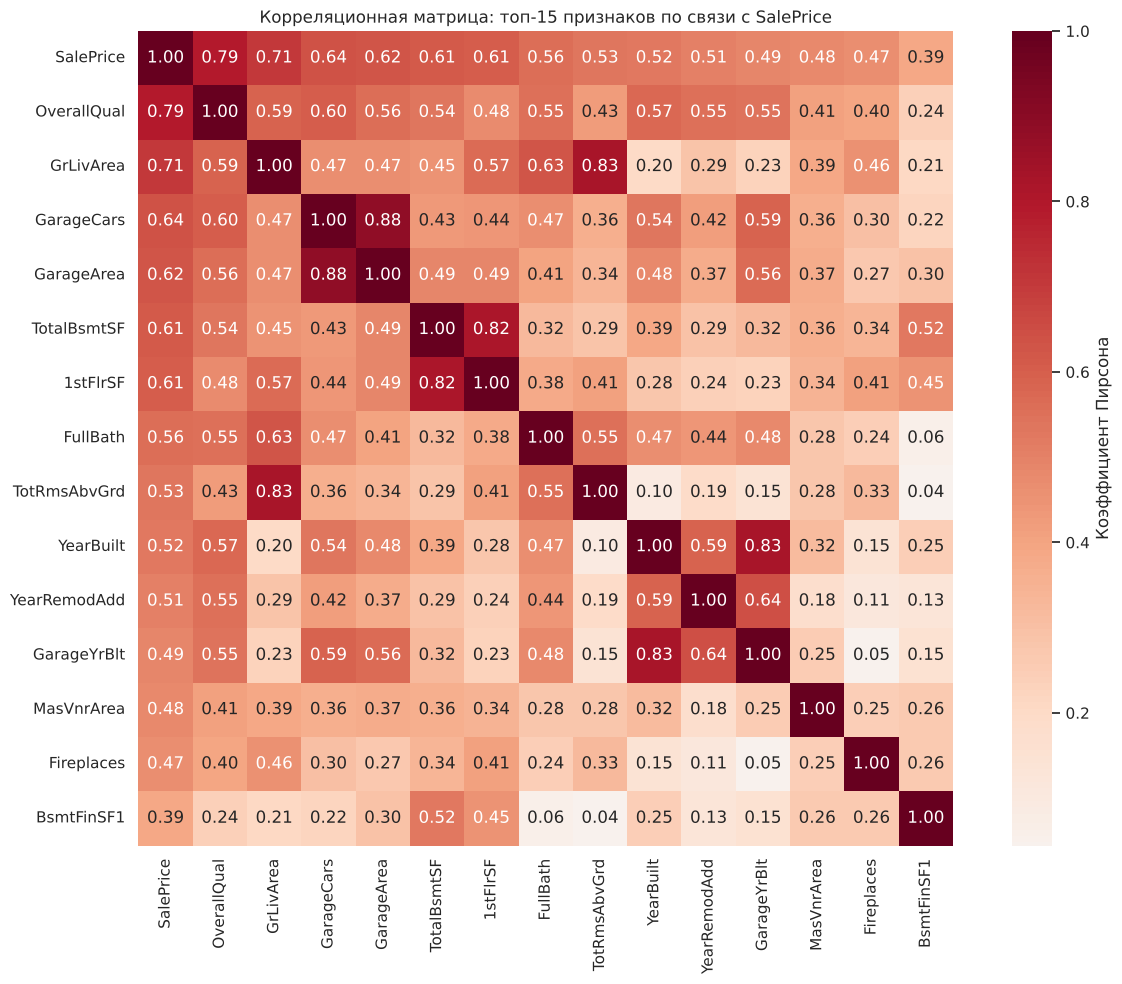

Мультиколлинеарные пары (|r| > 0.8):
      YearBuilt ↔ GarageYrBlt   r = 0.83
    TotalBsmtSF ↔ 1stFlrSF      r = 0.82
      GrLivArea ↔ TotRmsAbvGrd  r = 0.83
     GarageCars ↔ GarageArea    r = 0.88


In [10]:
# ===== Heatmap: корреляции 15 признаков, сильнее всего связанных с ценой =====
num_df = train_df.select_dtypes(include='number').drop(columns=['Id', 'SalePrice_log'])
top_corr = num_df.corr()['SalePrice'].abs().sort_values(ascending=False).head(15).index  # топ-15
plt.figure(figsize=(13, 10))
sns.heatmap(num_df[top_corr].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, cbar_kws={'label': 'Коэффициент Пирсона'})
plt.title('Корреляционная матрица: топ-15 признаков по связи с SalePrice')
plt.tight_layout()
plt.show()

# Пары с сильной мультиколлинеарностью (|r| > 0.8)
corr_m = num_df.corr()
pairs = [(a, b, corr_m.loc[a, b]) for i, a in enumerate(corr_m.columns)
         for b in corr_m.columns[i + 1:] if abs(corr_m.loc[a, b]) > 0.8 and 'SalePrice' not in (a, b)]
print('Мультиколлинеарные пары (|r| > 0.8):')
for a, b, r in pairs:
    print(f'  {a:>13} ↔ {b:<13} r = {r:.2f}')

**Наблюдения:** сильнее всего с ценой связаны `OverallQual` (r ≈ 0.79), `GrLivArea` (0.71), `GarageCars`/`GarageArea` (≈ 0.64), `TotalBsmtSF` и `1stFlrSF` (≈ 0.61). Найдены 4 пары с |r| > 0.8 — по сути дубли информации (`GarageCars ↔ GarageArea` = 0.88). Обычная линейная регрессия на таких данных даёт неустойчивые веса, поэтому основной упор — на Ridge/Lasso/ElasticNet.

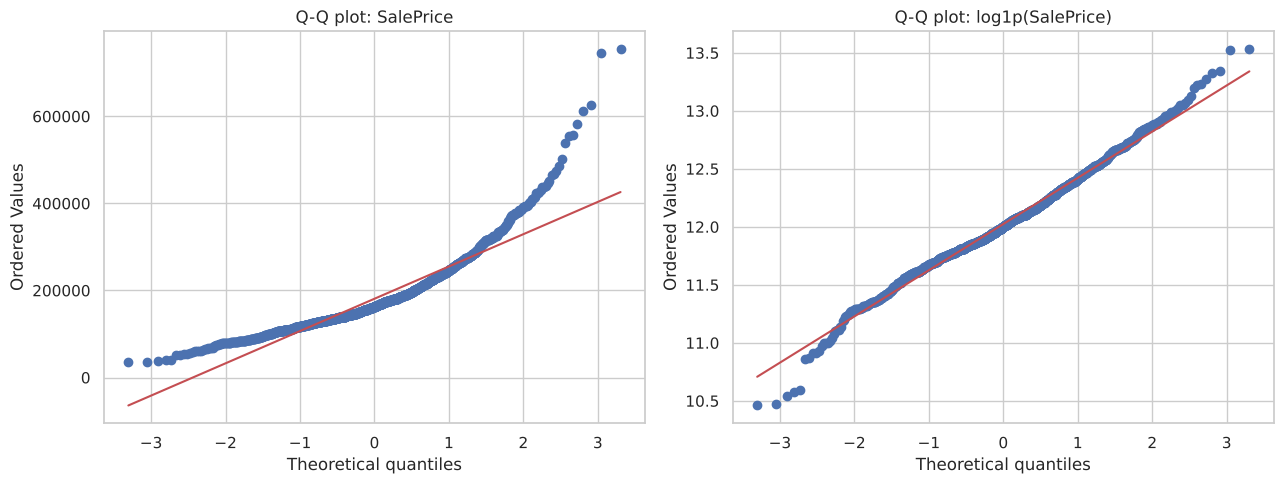

In [11]:
# ===== Q-Q plot: насколько распределение близко к нормальному =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(train_df['SalePrice'], dist='norm', plot=axes[0])       # до логарифмирования
axes[0].set_title('Q-Q plot: SalePrice')
stats.probplot(train_df['SalePrice_log'], dist='norm', plot=axes[1])   # после log1p
axes[1].set_title('Q-Q plot: log1p(SalePrice)')
plt.tight_layout()
plt.show()

На Q-Q plot исходные цены изгибаются вверх на правом конце (тяжёлый хвост), после log1p точки почти легли на прямую — распределение близко к нормальному.

### 5.4 Обработка выбросов
Выбросы удаляем **до** расчёта медиан/мод для заполнения пропусков, чтобы аномалии не исказили эти статистики.

In [12]:
# ===== Обработка выбросов =====
# 1) Статистический метод IQR для GrLivArea
q1, q3 = train_df['GrLivArea'].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr                                             # верхняя граница «усов»
iqr_out = train_df[train_df['GrLivArea'] > upper]
print(f'IQR: Q1={q1:.0f}, Q3={q3:.0f}, верхняя граница = {upper:.0f} кв. футов')
print(f'Формально по IQR выбросов: {len(iqr_out)} домов')

# 2) Доменные знания: огромный дом по цене обычного — ошибка/нерыночная сделка
domain_out = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
print(f'\nПо доменному правилу (>4000 футов и <$300k): {len(domain_out)} дома')
display(domain_out[['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'SaleCondition']])

# Удаляем только доменные выбросы: IQR-«выбросы» — это просто большие дорогие дома
n_before = len(train_df)
train_df = train_df.drop(domain_out.index).reset_index(drop=True)
print(f'Размер train: {n_before} → {len(train_df)}')

IQR: Q1=1130, Q3=1777, верхняя граница = 2748 кв. футов
Формально по IQR выбросов: 31 домов

По доменному правилу (>4000 футов и <$300k): 2 дома


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
1298,1299,5642,160000,10,Partial


Размер train: 1460 → 1458


**Обоснование.** Правило IQR формально помечает 31 дом, но это реальные большие дорогие дома — их удаление лишит модель информации о верхнем сегменте рынка. А вот 2 дома с площадью 4676 и 5642 кв. футов, качеством 10 и ценой \$160–185k — явная аномалия: тип продажи `Partial` (дом не достроен), цена не рыночная. Их удаляем (это же рекомендует автор датасета Dean De Cock). Обрабатываем только train — в test удалять строки нельзя.

### 5.5 Обработка пропусков

In [13]:
# ===== Обработка пропусков =====
# (а) Смысловые пропуски: NaN означает «объекта нет» → категория 'None'
NONE_COLS = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
# (б) Числовые «нет объекта» → 0 (нет гаража = 0 машин, нет подвала = 0 кв. футов)
ZERO_COLS = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

# Статистики для заполнения считаем ТОЛЬКО по train (без утечки из test)
lot_by_nbhd = train_df.groupby('Neighborhood')['LotFrontage'].median().to_dict()  # медиана по району
lot_global = float(train_df['LotFrontage'].median())
cat_all = [c for c in train_df.columns if train_df[c].dtype == object or str(train_df[c].dtype) in ('str', 'string')]
num_all = [c for c in train_df.select_dtypes(include='number').columns
           if c not in ('Id', 'SalePrice', 'SalePrice_log')]
mode_vals = {c: train_df[c].mode()[0] for c in cat_all}          # мода для категорий
median_vals = {c: float(train_df[c].median()) for c in num_all}  # медиана для чисел

def fill_missing(df):
    """Заполняет пропуски по трём стратегиям. Возвращает копию."""
    df = df.copy()
    for c in NONE_COLS:                                  # смысловые → 'None'
        df[c] = df[c].fillna('None')
    for c in ZERO_COLS:                                  # «нет объекта» → 0
        df[c] = df[c].fillna(0)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])   # нет гаража → год дома (не 0!)
    # LotFrontage (случайные пропуски) → медиана по району
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lot_by_nbhd)).fillna(lot_global)
    for c, v in mode_vals.items():                       # остальные категории → мода
        if c in df: df[c] = df[c].fillna(v)
    for c, v in median_vals.items():                     # остальные числа → медиана
        if c in df: df[c] = df[c].fillna(v)
    return df

train_df = fill_missing(train_df)
test_df = fill_missing(test_df)
print('Осталось пропусков в train:', int(train_df.isnull().sum().sum()))
print('Осталось пропусков в test: ', int(test_df.isnull().sum().sum()))

Осталось пропусков в train: 0
Осталось пропусков в test:  0


**Обоснование стратегий:**

| Группа | Столбцы | Стратегия | Почему |
|---|---|---|---|
| Смысловые категориальные | `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*`, `MasVnrType`, `MiscFeature` | `"None"` | По описанию датасета NaN = «нет бассейна/гаража/подвала»; это отдельная категория |
| Смысловые числовые | `GarageArea/Cars`, `Bsmt*SF`, `Bsmt*Bath`, `MasVnrArea` | `0` | Нет гаража → 0 машин, нет подвала → 0 кв. футов |
| `GarageYrBlt` | — | год постройки дома | Ноль дал бы абсурдный «гараж 0-го года» и выброс после масштабирования |
| Случайные (MAR) | `LotFrontage` | медиана **по району** | Ширина участка зависит от застройки района; общая медиана была бы грубее |
| Единичные | `Electrical` и пропуски в test (`MSZoning`, `KitchenQual`, ...) | мода / медиана | 1–4 значения, влияние минимально |

Все статистики посчитаны **только на train** и затем применены к test — так нет утечки информации.

### 5.6 Логарифмирование целевой

In [14]:
# ===== Логарифмирование целевой =====
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])  # log(1 + y): сжимает правый хвост
print(f"Skew до:    {train_df['SalePrice'].skew():.3f}")
print(f"Skew после: {train_df['SalePrice_log'].skew():.3f}")
# Обратное преобразование при предсказании: np.expm1(y_log) = exp(y_log) - 1

Skew до:    1.881
Skew после: 0.122


**Обоснование:** асимметрия упала с 1.88 до 0.12. Модель теперь минимизирует *относительную* ошибку: промах на 10% одинаково штрафуется для дома за \$100k и за \$500k. В разделе 7 проверим экспериментально, что без логарифма качество хуже.

### 5.7 Feature Engineering

In [15]:
# ===== Feature Engineering =====
def add_features(df):
    """Создаёт новые признаки из исходных. Возвращает копию."""
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']          # общая площадь
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])            # все санузлы
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch']
                        + df['ScreenPorch'] + df['WoodDeckSF'])                    # все крыльца/террасы
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)               # возраст дома
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)            # лет с ремонта
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)                              # бинарные флаги
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']                 # взаимодействие
    df['MSSubClass'] = pd.to_numeric(df['MSSubClass']).astype(int).astype(str)  # код типа дома — категория
    return df

train_df = add_features(train_df)
test_df = add_features(test_df)

new_feats = ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'HasPool',
             'HasGarage', 'Has2ndFloor', 'HasFireplace', 'OverallQual_TotalSF']
# Насколько новые признаки связаны с лог-ценой
fe_corr = train_df[new_feats + ['GrLivArea']].corrwith(train_df['SalePrice_log']).sort_values(ascending=False)
fe_corr.round(3).to_frame('corr с log(SalePrice)')

,corr с log(SalePrice)
OverallQual_TotalSF,0.883
TotalSF,0.825
GrLivArea,0.725
TotalBath,0.677
HasFireplace,0.510
TotalPorch,0.400
HasGarage,0.323
Has2ndFloor,0.151
HasPool,0.077
RemodAge,-0.569


Новые признаки оказались **сильнее исходных**: `OverallQual_TotalSF` (r = 0.88) и `TotalSF` (0.83) коррелируют с лог-ценой лучше, чем самый сильный исходный числовой признак `GrLivArea` (0.73). `HouseAge`/`RemodAge` — отрицательная связь: чем старше дом и давнее ремонт, тем дешевле. `HasPool` почти не связан с ценой — бассейнов всего 7.

### 5.8 Кодирование категориальных признаков

In [16]:
# ===== Кодирование категориальных признаков =====
# (а) Порядковые признаки → числа с ручным маппингом (порядок важен!)
QUAL_MAP = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}   # Poor → Excellent
ORDINAL_MAPS = {
    **{c: QUAL_MAP for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']},
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},
    'CentralAir': {'N': 0, 'Y': 1},
}

def encode_ordinal(df):
    """Label Encoding порядковых признаков по словарям. Неизвестное значение → 0."""
    df = df.copy()
    for c, m in ORDINAL_MAPS.items():
        df[c] = df[c].map(m).fillna(0).astype(int)
    return df

train_df = encode_ordinal(train_df)
test_df = encode_ordinal(test_df)

# (б) Номинальные признаки (без порядка) → One-Hot
NOMINAL_COLS = [c for c in train_df.columns
                if not pd.api.types.is_numeric_dtype(train_df[c])]
print(f'Порядковых (Label Encoding): {len(ORDINAL_MAPS)}')
print(f'Номинальных (One-Hot):       {len(NOMINAL_COLS)} → {NOMINAL_COLS[:8]} ...')

Порядковых (Label Encoding): 17
Номинальных (One-Hot):       27 → ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig'] ...


- **Порядковые** признаки (оценки качества `Po < Fa < TA < Gd < Ex` и т.п.) кодируем числами вручную — так сохраняется порядок, и модель может выучить «чем лучше кухня, тем дороже» одним весом.
- **Номинальные** (`Neighborhood`, `MSZoning`, ...) порядка не имеют — кодируем One-Hot, иначе модель решила бы, что район №7 «больше» района №3.
- `MSSubClass` — числовой код типа здания (20, 60, ...), но по смыслу это категория, поэтому переведён в строку.

In [17]:
# ===== Логарифмирование скошенных числовых признаков =====
# Линейные модели лучше работают, когда признаки не имеют длинных «хвостов»
num_feats = [c for c in train_df.select_dtypes(include='number').columns
             if c not in ('Id', 'SalePrice', 'SalePrice_log') and train_df[c].nunique() > 10]
feat_skew = train_df[num_feats].skew().sort_values(ascending=False)
SKEWED_COLS = [c for c in feat_skew.index
               if abs(feat_skew[c]) > 0.75 and train_df[c].min() >= 0]   # только неотрицательные
print(f'Скошенных признаков (|skew| > 0.75): {len(SKEWED_COLS)}')
print(feat_skew[SKEWED_COLS].head(10).round(2).to_string())

def log_skewed(df):
    df = df.copy()
    for c in SKEWED_COLS:
        df[c] = np.log1p(df[c].clip(lower=0))    # clip: защита от отрицательных во входных данных
    return df

Скошенных признаков (|skew| > 0.75): 19
MiscVal          24.46
LotArea          12.57
3SsnPorch        10.30
LowQualFinSF      9.00
BsmtFinSF2        4.25
ScreenPorch       4.12
EnclosedPorch     3.09
MasVnrArea        2.70
OpenPorchSF       2.34
LotFrontage       1.55


In [18]:
# ===== Итоговая матрица признаков =====
def build_matrix(df, columns=None):
    """Логарифмирует скошенные признаки + One-Hot. columns — эталонный порядок столбцов."""
    df = log_skewed(df)
    X = pd.get_dummies(df.drop(columns=[c for c in ('Id', 'SalePrice', 'SalePrice_log') if c in df]),
                       columns=NOMINAL_COLS, dtype=int)
    if columns is not None:                       # для test/новых домов — те же столбцы, что в train
        X = X.reindex(columns=columns, fill_value=0)
    return X

X = build_matrix(train_df)                         # признаки train
feature_cols = X.columns.tolist()                  # фиксируем порядок признаков
X_kaggle = build_matrix(test_df, feature_cols)     # тест Kaggle в том же формате
y = train_df['SalePrice_log']                      # целевая — ЛОГ-цена!

print('X:', X.shape, '| X_kaggle:', X_kaggle.shape, '| y:', y.shape)
print('NaN в X:', int(X.isnull().sum().sum()))

X: (1458, 257) | X_kaggle: (1459, 257) | y: (1458,)
NaN в X: 0


In [19]:
# ===== Единая функция предобработки «сырых» данных (нужна для predict_price) =====
def preprocess(raw_df):
    """Полный пайплайн: пропуски → FE → кодирование → log → One-Hot → порядок feature_cols."""
    df = fill_missing(raw_df)
    df = add_features(df)
    df = encode_ordinal(df)
    return build_matrix(df, feature_cols)

# Проверка: пайплайн на сырых данных даёт ту же матрицу, что пошаговая обработка
raw_check = pd.read_csv('data/train.csv').drop(domain_out.index).reset_index(drop=True)
assert np.allclose(preprocess(raw_check).values, X.values), 'Пайплайн не совпадает!'
print('✅ preprocess() воспроизводит пошаговую обработку')

✅ preprocess() воспроизводит пошаговую обработку


**Итог предобработки:** 1458 домов × **257 признаков**, пропусков нет. Тест Kaggle приведён к тем же 257 столбцам (категории, которых не было в train, получают нули). Весь пайплайн собран в функцию `preprocess()`, и проверено, что она даёт ту же матрицу, — это гарантирует, что новый дом в `predict_price()` будет обработан точно так же, как обучающие.

## Построение и обучение моделей

Разделяем данные 80/20, масштабируем `StandardScaler` (обучаем его только на train) и обучаем модели. Гиперпараметры Ridge, Lasso и ElasticNet подбираются `GridSearchCV` с 5-fold кросс-валидацией по RMSE.

In [20]:
# ===== Разделение и масштабирование =====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)           # 80% обучение / 20% проверка

scaler = StandardScaler()                                      # среднее 0, std 1
X_train_scaled = scaler.fit_transform(X_train)                 # fit — только на train!
X_test_scaled = scaler.transform(X_test)                       # test — тем же scaler
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # 5-fold кросс-валидация
train_times = {}                                                  # сюда пишем время обучения

Train: (1166, 257), Test: (292, 257)


In [21]:
# ===== 1. Linear Regression (базовая модель) =====
lr_model = LinearRegression()
start = time.time()
lr_model.fit(X_train_scaled, y_train)
train_times['Linear Regression'] = time.time() - start
print(f"⏱️ Время обучения LR: {train_times['Linear Regression']:.3f} секунд")

⏱️ Время обучения LR: 0.048 секунд


In [22]:
# ===== 2. Ridge (L2) — подбор alpha через GridSearchCV =====
ridge_grid = GridSearchCV(Ridge(random_state=RANDOM_STATE),
                          {'alpha': [1, 5, 10, 30, 60, 100, 200, 400, 800]},
                          cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_train_scaled, y_train)
print('Лучший alpha Ridge:', ridge_grid.best_params_['alpha'],
      f'| CV RMSE = {-ridge_grid.best_score_:.4f}')

ridge_model = Ridge(alpha=ridge_grid.best_params_['alpha'], random_state=RANDOM_STATE)
start = time.time()
ridge_model.fit(X_train_scaled, y_train)                       # финальное обучение
train_times['Ridge'] = time.time() - start
print(f"⏱️ Время обучения Ridge: {train_times['Ridge']:.3f} секунд")

Лучший alpha Ridge: 200 | CV RMSE = 0.1172
⏱️ Время обучения Ridge: 0.009 секунд


In [23]:
# ===== 3. Lasso (L1) — подбор alpha =====
lasso_grid = GridSearchCV(Lasso(max_iter=50000, random_state=RANDOM_STATE),
                          {'alpha': [0.0005, 0.001, 0.002, 0.003, 0.005, 0.008, 0.01]},
                          cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_train_scaled, y_train)
print('Лучший alpha Lasso:', lasso_grid.best_params_['alpha'],
      f'| CV RMSE = {-lasso_grid.best_score_:.4f}')

lasso_model = Lasso(alpha=lasso_grid.best_params_['alpha'], max_iter=50000, random_state=RANDOM_STATE)
start = time.time()
lasso_model.fit(X_train_scaled, y_train)
train_times['Lasso'] = time.time() - start
print(f"⏱️ Время обучения Lasso: {train_times['Lasso']:.3f} секунд")

Лучший alpha Lasso: 0.005 | CV RMSE = 0.1134
⏱️ Время обучения Lasso: 0.022 секунд


In [24]:
# ===== 4. ElasticNet (L1 + L2) — подбор alpha и l1_ratio =====
enet_grid = GridSearchCV(ElasticNet(max_iter=50000, random_state=RANDOM_STATE),
                         {'alpha': [0.001, 0.003, 0.005, 0.01, 0.02],
                          'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]},
                         cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
enet_grid.fit(X_train_scaled, y_train)
print('Лучшие параметры ElasticNet:', enet_grid.best_params_,
      f'| CV RMSE = {-enet_grid.best_score_:.4f}')

enet_model = ElasticNet(**enet_grid.best_params_, max_iter=50000, random_state=RANDOM_STATE)
start = time.time()
enet_model.fit(X_train_scaled, y_train)
train_times['ElasticNet'] = time.time() - start
print(f"⏱️ Время обучения ElasticNet: {train_times['ElasticNet']:.3f} секунд")

Лучшие параметры ElasticNet: {'alpha': 0.005, 'l1_ratio': 0.7} | CV RMSE = 0.1132
⏱️ Время обучения ElasticNet: 0.026 секунд


### Бонус: модели градиентного бустинга и стекинг

In [25]:
# ===== БОНУС: XGBoost, LightGBM и Stacking =====
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import StackingRegressor

# XGBoost: градиентный бустинг деревьев (масштабирование не обязательно, но не мешает)
xgb_model = XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=3, subsample=0.8,
                         colsample_bytree=0.5, reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1)
start = time.time()
xgb_model.fit(X_train_scaled, y_train)
train_times['XGBoost'] = time.time() - start

# LightGBM: быстрый бустинг с ростом дерева «по листьям»
lgbm_model = LGBMRegressor(n_estimators=2000, learning_rate=0.02, num_leaves=8, min_child_samples=10,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                           random_state=RANDOM_STATE, verbose=-1)
start = time.time()
lgbm_model.fit(X_train_scaled, y_train)
train_times['LightGBM'] = time.time() - start

# Stacking: базовые модели Ridge + Lasso + XGBoost, мета-модель — Ridge
stack_model = StackingRegressor(
    estimators=[('ridge', ridge_model), ('lasso', lasso_model), ('xgb', xgb_model)],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1)
start = time.time()
stack_model.fit(X_train_scaled, y_train)
train_times['Stacking'] = time.time() - start

for name in ['XGBoost', 'LightGBM', 'Stacking']:
    print(f'⏱️ Время обучения {name}: {train_times[name]:.2f} секунд')

⏱️ Время обучения XGBoost: 1.48 секунд
⏱️ Время обучения LightGBM: 1.35 секунд
⏱️ Время обучения Stacking: 6.32 секунд


In [26]:
# ===== Сводная таблица моделей =====
models = {'Linear Regression': lr_model, 'Ridge': ridge_model, 'Lasso': lasso_model,
          'ElasticNet': enet_model, 'XGBoost': xgb_model, 'LightGBM': lgbm_model,
          'Stacking': stack_model}
params = {'Linear Regression': '—',
          'Ridge': f"alpha={ridge_model.alpha}",
          'Lasso': f"alpha={lasso_model.alpha}",
          'ElasticNet': f"alpha={enet_model.alpha}, l1_ratio={enet_model.l1_ratio}",
          'XGBoost': 'n=2000, lr=0.03, depth=3',
          'LightGBM': 'n=2000, lr=0.02, leaves=8',
          'Stacking': 'Ridge+Lasso+XGB → Ridge'}
pd.DataFrame({'Параметры': params, 'Время обучения, с': pd.Series(train_times).round(3)})

,Параметры,"Время обучения, с"
Linear Regression,—,0.048
Ridge,alpha=200,0.009
Lasso,alpha=0.005,0.022
ElasticNet,"alpha=0.005, l1_ratio=0.7",0.026
XGBoost,"n=2000, lr=0.03, depth=3",1.480
LightGBM,"n=2000, lr=0.02, leaves=8",1.347
Stacking,Ridge+Lasso+XGB → Ridge,6.323


| Модель | Параметры (подобраны CV) | Масштабирование | Время обучения |
|--------|-----------|-----------------|----------------|
| Linear Regression | — | ✅ Да | < 0.05 с |
| Ridge | alpha = 200 | ✅ Да | < 0.05 с |
| Lasso | alpha = 0.005 | ✅ Да | < 0.05 с |
| ElasticNet | alpha = 0.005, l1_ratio = 0.7 | ✅ Да | < 0.05 с |
| XGBoost *(бонус)* | 2000 деревьев, глубина 3 | не обязательно | ≈ 1–2 с |
| LightGBM *(бонус)* | 2000 деревьев, 8 листьев | не обязательно | ≈ 1–2 с |
| Stacking *(бонус)* | Ridge + Lasso + XGB → Ridge | ✅ Да | ≈ 6–8 с |

*(точное время — в таблице выше, оно немного меняется от запуска к запуску)*

**Почему эти модели:**
- **LR** — базовая линия: показывает, что даёт линейная модель без регуляризации.
- **Ridge** — уменьшает веса при мультиколлинеарности (`GarageCars ↔ GarageArea`, `GrLivArea ↔ TotRmsAbvGrd`). Подобранный alpha = 200 большой — признак того, что регуляризация действительно нужна при 257 признаках.
- **Lasso** — обнуляет неинформативные признаки (большинство dummy-столбцов редких категорий).
- **ElasticNet** — компромисс: CV выбрал `l1_ratio = 0.7`, т.е. в основном L1 с небольшой долей L2.
- **XGBoost / LightGBM** — нелинейные модели, сами находят взаимодействия признаков.
- **Stacking** — объединяет сильные стороны линейных моделей и бустинга.

Масштабирование обязательно для регуляризованных моделей: штраф $\alpha\sum w_j^2$ зависит от масштаба признака, и без него площадь в квадратных футах «штрафовалась» бы иначе, чем флаг 0/1.

## Оценка качества

Все метрики — на отложенных 20% (292 дома), которые модели не видели при обучении. Дополнительно приведён RMSE 5-fold кросс-валидации на всём train — он устойчивее к случайности разбиения.

In [27]:
# ===== Метрики качества на отложенной выборке (20%) =====
y_test_real = np.expm1(y_test)                       # реальные цены в долларах

def evaluate_model(model, X_te, y_te, model_name):
    """Считает метрики в log-пространстве и в долларах."""
    y_pred_log = model.predict(X_te)                 # предсказание log-цены
    y_pred_real = np.expm1(y_pred_log)               # обратно в доллары
    return {
        'Модель': model_name,
        'RMSE (log)': np.sqrt(mean_squared_error(y_te, y_pred_log)),
        'MAE (log)': mean_absolute_error(y_te, y_pred_log),
        'R² (log)': r2_score(y_te, y_pred_log),
        'RMSE ($)': np.sqrt(mean_squared_error(np.expm1(y_te), y_pred_real)),
        'MAE ($)': mean_absolute_error(np.expm1(y_te), y_pred_real),
        'R² ($)': r2_score(np.expm1(y_te), y_pred_real),
    }

results = pd.DataFrame([evaluate_model(m, X_test_scaled, y_test, n) for n, m in models.items()])
results = results.set_index('Модель')

# 5-fold CV RMSE на всём train (устойчивее одного разбиения); Stacking пропускаем — долго
X_all_scaled_cv = StandardScaler().fit_transform(X)  # только для CV-оценки
cv_rmse = {}
for n, m in models.items():
    if n == 'Stacking':
        continue
    cv_rmse[n] = -cross_val_score(m, X_all_scaled_cv, y, cv=kf,
                                  scoring='neg_root_mean_squared_error', n_jobs=-1).mean()
results['CV RMSE (log)'] = pd.Series(cv_rmse)

fmt = {'RMSE (log)': '{:.4f}', 'MAE (log)': '{:.4f}', 'R² (log)': '{:.4f}', 'R² ($)': '{:.4f}',
       'RMSE ($)': '${:,.0f}', 'MAE ($)': '${:,.0f}', 'CV RMSE (log)': '{:.4f}'}
results.style.format(fmt, na_rep='—').highlight_min(subset=['RMSE (log)', 'RMSE ($)'], color='#c8f7c5')

,RMSE (log),MAE (log),R² (log),RMSE ($),MAE ($),R² ($),CV RMSE (log)
Модель,,,,,,,
Linear Regression,0.1292,0.0880,0.9010,"$21,443","$15,025",0.9168,0.1348
Ridge,0.1181,0.0844,0.9173,"$21,514","$15,000",0.9162,0.1175
Lasso,0.1121,0.0801,0.9255,"$19,613","$14,069",0.9304,0.1134
ElasticNet,0.1116,0.0800,0.9261,"$19,699","$14,048",0.9297,0.1131
XGBoost,0.1125,0.0788,0.9250,"$18,689","$13,673",0.9368,0.1136
LightGBM,0.1215,0.0807,0.9125,"$19,057","$13,761",0.9343,0.1166
Stacking,0.1077,0.0751,0.9312,"$18,223","$12,950",0.9399,—


🏆 Лучшая линейная модель: ElasticNet (RMSE log = 0.1116, R² = 0.9261)
🏆 Лучшая модель среди всех: Stacking (RMSE log = 0.1077)


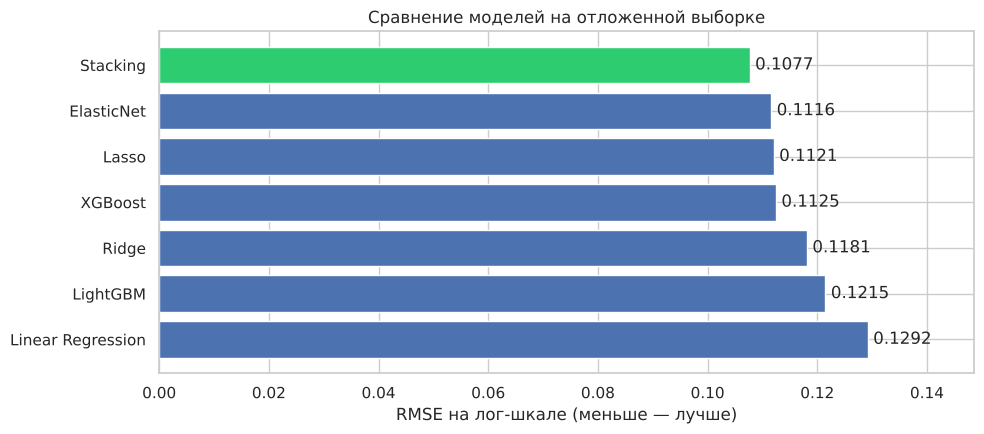

In [28]:
# ===== Выбор лучшей модели =====
linear_names = ['Linear Regression', 'Ridge', 'Lasso', 'ElasticNet']
best_linear_name = results.loc[linear_names, 'RMSE (log)'].idxmin()   # лучшая из 4 обязательных
best_overall_name = results['RMSE (log)'].idxmin()                   # лучшая среди всех
best_model = models[best_linear_name]
print(f'🏆 Лучшая линейная модель: {best_linear_name} '
      f"(RMSE log = {results.loc[best_linear_name, 'RMSE (log)']:.4f}, "
      f"R² = {results.loc[best_linear_name, 'R² (log)']:.4f})")
print(f'🏆 Лучшая модель среди всех: {best_overall_name} '
      f"(RMSE log = {results.loc[best_overall_name, 'RMSE (log)']:.4f})")

# Сравнительная диаграмма RMSE (log)
plt.figure(figsize=(10, 4.5))
order = results['RMSE (log)'].sort_values()
colors = ['#2ecc71' if n == best_overall_name else '#4C72B0' for n in order.index]
plt.barh(order.index, order.values, color=colors)
for i, v in enumerate(order.values):
    plt.text(v + 0.001, i, f'{v:.4f}', va='center')
plt.xlabel('RMSE на лог-шкале (меньше — лучше)')
plt.title('Сравнение моделей на отложенной выборке')
plt.xlim(0, order.max() * 1.15)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

| Модель | RMSE (log) | MAE (log) | R² | RMSE (\$) | CV RMSE (log) |
|--------|-----------|-----------|-----|---------|---|
| Linear Regression | 0.129 | 0.088 | 0.901 | \$21 443 | 0.135 |
| Ridge | 0.118 | 0.084 | 0.917 | \$21 514 | 0.118 |
| Lasso | 0.112 | 0.080 | 0.926 | \$19 613 | 0.113 |
| **ElasticNet** | **0.112** | **0.080** | **0.926** | \$19 699 | **0.113** |
| XGBoost *(бонус)* | 0.113 | 0.079 | 0.925 | \$18 689 | 0.114 |
| LightGBM *(бонус)* | 0.122 | 0.081 | 0.913 | \$19 057 | 0.117 |
| **Stacking** *(бонус)* | **0.108** | **0.075** | **0.931** | **\$18 223** | — |

**Анализ:**
- **Цель R² ≥ 0.90 достигнута всеми моделями.** Лучшая из обязательных — **ElasticNet** (RMSE log = 0.112, R² = 0.926), Lasso практически вровень (разница в 4-м знаке). Лучшая в целом — **Stacking** (RMSE log = 0.108, R² = 0.931).
- **Регуляризация работает:** LR без штрафа хуже всех и по тесту, и особенно по CV (0.135 против 0.113) — её веса неустойчивы из-за мультиколлинеарности.
- **Lasso/ElasticNet лучше Ridge** — значит, многие из 257 признаков шумовые, и их обнуление полезно (подробнее — раздел 8).
- XGBoost сопоставим с лучшими линейными, но не превосходит их: после логарифмирования и FE зависимость уже почти линейная. Зато ошибки бустинга и линейных моделей разные, поэтому их **стекинг** даёт лучший результат.
- Ошибка RMSE ≈ \$19–20k при средней цене \$181k — около 11%; средняя относительная ошибка лучшей линейной модели ≈ 8%.

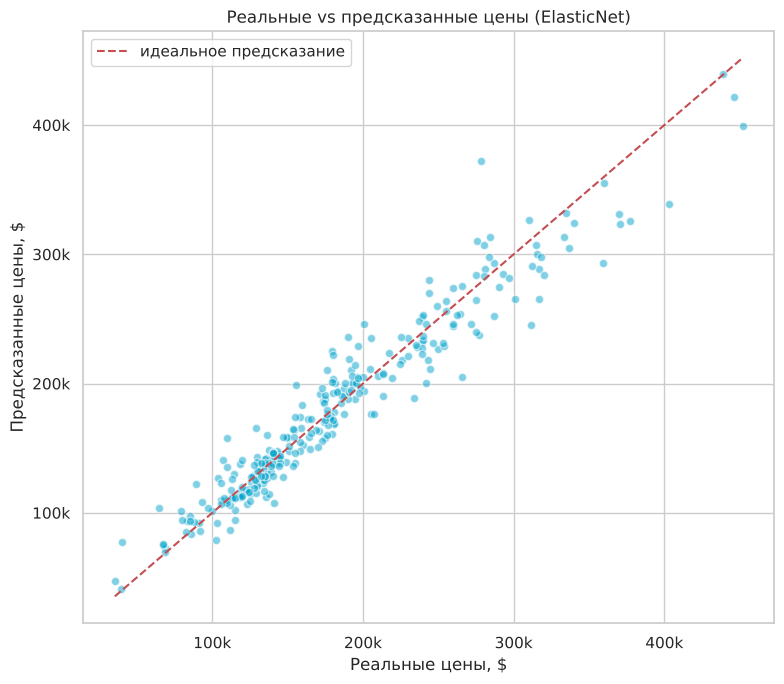

In [29]:
# ===== График «Реальные vs Предсказанные» (лучшая линейная модель) =====
y_pred_best = np.expm1(best_model.predict(X_test_scaled))     # предсказания в долларах

plt.figure(figsize=(8, 7))
plt.scatter(y_test_real, y_pred_best, alpha=0.5, color='#00a3cc', edgecolor='white', s=35)
lims = [y_test_real.min(), y_test_real.max()]
plt.plot(lims, lims, 'r--', label='идеальное предсказание')    # диагональ y = x
plt.xlabel('Реальные цены, $')
plt.ylabel('Предсказанные цены, $')
plt.gca().xaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')   # подписи в тысячах
plt.gca().yaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')
plt.title(f'Реальные vs предсказанные цены ({best_linear_name})')
plt.legend()
plt.tight_layout()
plt.savefig('examples/predictions_scatter.png', dpi=110)
plt.show()

Точки плотно лежат вдоль диагонали во всём диапазоне цен. На дорогих домах (> \$350k) разброс больше — таких примеров в данных мало.

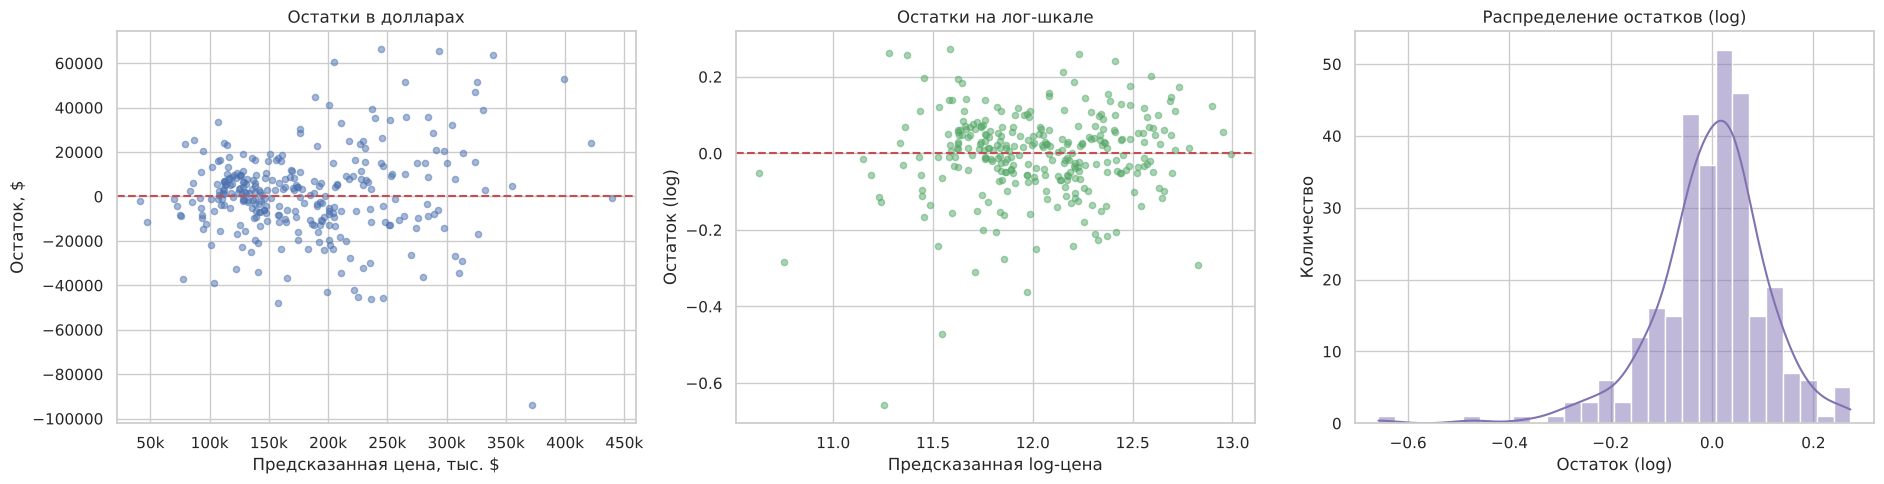

Среднее остатков: $1,173
Std остатков:     $19,698
Медиана |ошибки|: $9,273
Средняя ошибка в %: 8.2%


,Реальная,Предсказание,"Ошибка, $",Id,OverallQual,GrLivArea,Neighborhood,SaleCondition
1043,278000.0,372087.0,-94087.0,1045,8,2524,NWAmes,Normal
218,311500.0,245028.0,66472.0,219,7,1954,Crawfor,Normal
607,359100.0,293585.0,65515.0,609,8,3194,Crawfor,Alloca
231,403000.0,339229.0,63771.0,232,8,2794,NoRidge,Normal
746,265979.0,205284.0,60695.0,748,7,2640,OldTown,Normal


In [30]:
# ===== Анализ остатков =====
residuals = y_test_real - y_pred_best                          # ошибка в долларах
residuals_log = y_test - best_model.predict(X_test_scaled)     # ошибка на лог-шкале

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
# 1) Остатки vs предсказания: ищем «воронку» (гетероскедастичность)
axes[0].scatter(y_pred_best, residuals, alpha=0.5, s=20)
axes[0].axhline(0, color='r', linestyle='--')
axes[0].set(xlabel='Предсказанная цена, тыс. $', ylabel='Остаток, $', title='Остатки в долларах')
axes[0].xaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')   # 150000 → 150k
# 2) То же на лог-шкале — здесь разброс должен быть ровнее
axes[1].scatter(best_model.predict(X_test_scaled), residuals_log, alpha=0.5, s=20, color='#55A868')
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set(xlabel='Предсказанная log-цена', ylabel='Остаток (log)', title='Остатки на лог-шкале')
# 3) Распределение остатков
sns.histplot(residuals_log, kde=True, ax=axes[2], color='#8172B2')
axes[2].set(xlabel='Остаток (log)', ylabel='Количество', title='Распределение остатков (log)')
plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=110)
plt.show()

print(f'Среднее остатков: ${residuals.mean():,.0f}')
print(f'Std остатков:     ${residuals.std():,.0f}')
print(f'Медиана |ошибки|: ${residuals.abs().median():,.0f}')
print(f'Средняя ошибка в %: {(residuals.abs() / y_test_real).mean() * 100:.1f}%')

# Худшие предсказания — для разбора
worst = pd.DataFrame({'Реальная': y_test_real, 'Предсказание': y_pred_best.round(0),
                      'Ошибка, $': residuals.round(0)}).loc[residuals.abs().sort_values(ascending=False).index[:5]]
worst.join(train_df[['Id', 'OverallQual', 'GrLivArea', 'Neighborhood', 'SaleCondition']])

**Анализ остатков:**
- Среднее остатков ≈ \$1 200 — практически 0, систематического завышения/занижения нет.
- В долларах разброс остатков растёт с ценой («воронка»), а **на лог-шкале он ровный** — именно поэтому мы учили модель на `log1p`: ошибка пропорциональна цене, а не постоянна.
- Распределение остатков на лог-шкале колоколообразное с центром в 0, но с небольшим **левым хвостом**: несколько домов модель сильно *переоценила* (остаток до −0.66, т.е. цена почти вдвое ниже прогноза). Это нетипичные сделки, а не систематическая ошибка — основная масса остатков в пределах ±0.2 (≈ ±20%).
- Крупнейшие промахи (до \$94k) — дома с высоким качеством (7–8) в районах `Crawfor`, `NWAmes`, `OldTown`, где цены сильно варьируются: модель не знает о конкретных особенностях (вид, ремонт, состояние), которых нет в признаках. Один из них продан по условиям `Alloca` (совмещённые участки) — нетипичная сделка.

In [31]:
# ===== Эксперимент: что будет БЕЗ логарифмирования целевой? =====
y_train_raw, y_test_raw = np.expm1(y_train), np.expm1(y_test)       # цены в долларах
ridge_raw = Ridge(alpha=ridge_model.alpha).fit(X_train_scaled, y_train_raw)
pred_raw = ridge_raw.predict(X_test_scaled)
print(f"Ridge на сырых ценах:   R² = {r2_score(y_test_raw, pred_raw):.4f}, "
      f"RMSE = ${np.sqrt(mean_squared_error(y_test_raw, pred_raw)):,.0f}")
print(f"Ridge на log1p(цены):   R² = {results.loc['Ridge', 'R² ($)']:.4f}, "
      f"RMSE = ${results.loc['Ridge', 'RMSE ($)']:,.0f}")
print(f"Отрицательных цен без log: {(pred_raw < 0).sum()} шт.; минимальное предсказание ${pred_raw.min():,.0f}")

Ridge на сырых ценах:   R² = 0.8651, RMSE = $27,294
Ridge на log1p(цены):   R² = 0.9162, RMSE = $21,514
Отрицательных цен без log: 1 шт.; минимальное предсказание $-26,429


**Эксперимент подтверждает пользу логарифмирования:** тот же Ridge на «сырых» ценах даёт R² 0.865 против 0.916 и ошибку на ~\$6 000 больше; кроме того, он предсказывает **отрицательную** цену для одного дома — с лог-шкалой это невозможно в принципе.

## Интерпретация результатов

### 8.1 Коэффициенты Ridge

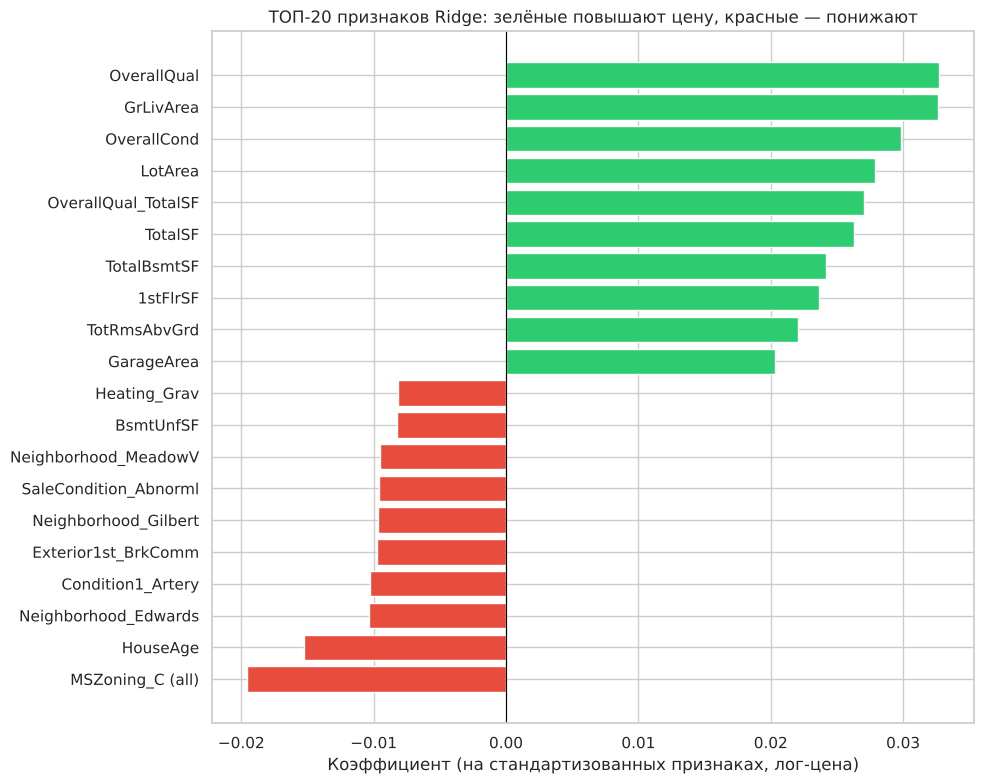

In [32]:
# ===== Коэффициенты Ridge: ТОП-10 «+» и ТОП-10 «−» =====
coefficients = pd.DataFrame({'Feature': feature_cols, 'Coefficient': ridge_model.coef_})
coefficients = coefficients.sort_values('Coefficient', ascending=False)
top = pd.concat([coefficients.head(10), coefficients.tail(10)])      # 10 сильнейших в каждую сторону

plt.figure(figsize=(10, 8))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top['Coefficient']]
plt.barh(top['Feature'], top['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel('Коэффициент (на стандартизованных признаках, лог-цена)')
plt.title('ТОП-20 признаков Ridge: зелёные повышают цену, красные — понижают')
plt.tight_layout()
plt.show()

Признаки стандартизованы, поэтому коэффициенты можно сравнивать между собой: коэффициент 0.05 означает, что рост признака на одно стандартное отклонение увеличивает цену примерно на 5%.

### 8.2 Отбор признаков Lasso

In [33]:
# ===== Отбор признаков Lasso =====
n_zero = int((lasso_model.coef_ == 0).sum())
n_total = len(lasso_model.coef_)
print(f'Lasso обнулил: {n_zero} из {n_total} признаков')
print(f'Осталось значимых: {n_total - n_zero}')

lasso_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': lasso_model.coef_})
non_zero = lasso_coef[lasso_coef['Coefficient'] != 0].sort_values('Coefficient', ascending=False)
print('\nТОП-15 признаков, повышающих цену (Lasso):')
print(non_zero.head(15).round(4).to_string(index=False))
print('\nТОП-10 признаков, понижающих цену (Lasso):')
print(non_zero.tail(10).sort_values('Coefficient').round(4).to_string(index=False))

Lasso обнулил: 187 из 257 признаков
Осталось значимых: 70

ТОП-15 признаков, повышающих цену (Lasso):
             Feature  Coefficient
           GrLivArea       0.1059
         OverallQual       0.0718
             LotArea       0.0376
         TotalBsmtSF       0.0344
         OverallCond       0.0344
           TotalBath       0.0318
          GarageArea       0.0282
          Functional       0.0180
         KitchenQual       0.0174
          BsmtFinSF1       0.0170
          Fireplaces       0.0169
Neighborhood_Crawfor       0.0162
        SaleType_New       0.0154
Neighborhood_StoneBr       0.0145
 Exterior1st_BrkFace       0.0128

ТОП-10 признаков, понижающих цену (Lasso):
              Feature  Coefficient
             HouseAge      -0.0424
     MSZoning_C (all)      -0.0176
             RemodAge      -0.0130
         KitchenAbvGr      -0.0110
SaleCondition_Abnorml      -0.0102
    Condition1_Artery      -0.0089
          MSZoning_RM      -0.0087
      RoofStyle_Gable      -0.

Lasso оставил **70 из 257 признаков** (обнулил 187, т.е. 73%) — в основном dummy-столбцы редких категорий (экзотические материалы крыши, типы отопления и т.п.), которые не несут устойчивой информации. При этом качество не упало, а выросло по сравнению с Ridge.

### 8.3 Важность признаков в XGBoost

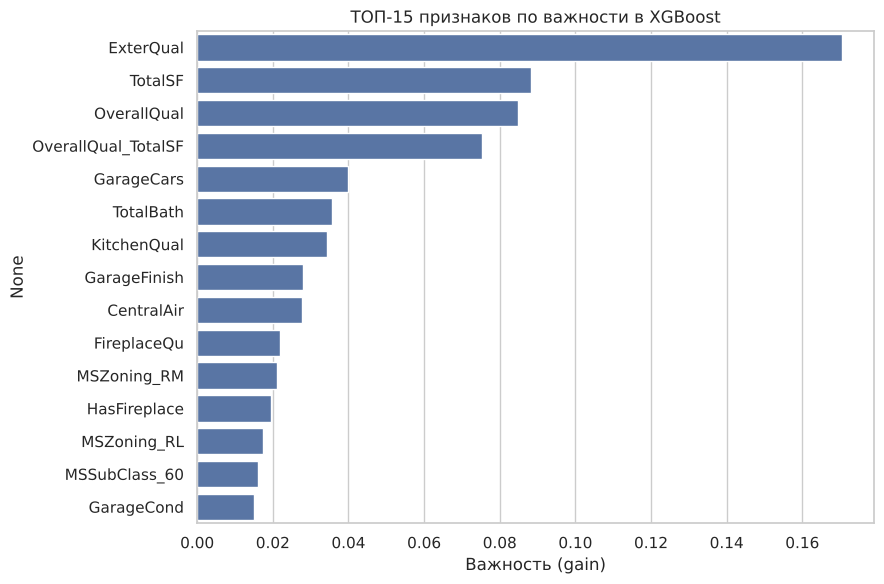

In [34]:
# ===== Важность признаков в XGBoost (нелинейный взгляд) =====
xgb_imp = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, color='#4C72B0')
plt.xlabel('Важность (gain)')
plt.title('ТОП-15 признаков по важности в XGBoost')
plt.tight_layout()
plt.show()

### 8.4 Выводы по интерпретации

**Топ-5 признаков, повышающих цену** (по Lasso и XGBoost):
1. **GrLivArea / TotalSF** — площадь (жилая и общая) — главный драйвер цены.
2. **OverallQual** — общее качество; в XGBoost и взаимодействие `OverallQual_TotalSF` — признак №1.
3. **TotalBath, GarageArea/GarageCars** — число санузлов и гараж.
4. **OverallCond, KitchenQual, Functional** — состояние дома и качество кухни.
5. **Neighborhood_Crawfor / StoneBr / NridgHt** — престижные районы, **SaleType_New** — новостройки.

**Топ-5 признаков, понижающих цену:**
1. **HouseAge** — возраст дома (сильнейший отрицательный коэффициент Lasso).
2. **MSZoning_C (all)** — коммерческая зона: жить рядом с бизнесом менее привлекательно.
3. **RemodAge** — давно не было ремонта.
4. **SaleCondition_Abnorml** — вынужденная продажа (банкротство, обмен), продают с дисконтом.
5. **Condition1_Artery, KitchenAbvGr** — дом у оживлённой магистрали; несколько кухонь (обычно дуплексы под сдачу).

**Бизнес-инсайты** (для типичного дома за ≈ \$170k; расчёт «что если» с помощью `predict_price()` — в конце раздела 9):
- Каждый **балл OverallQual** добавляет ≈ **+5%** (≈ \$8 500) *при прочих равных*; в сырых данных разница больше, потому что качественные дома ещё и больше по площади.
- **+300 кв. футов** жилой площади ≈ **+6%** (≈ \$10 700).
- **Место для третьей машины** в гараже ≈ +5%, **кухня Excellent** ≈ +5%, **камин** ≈ +3%.
- **Район** решает: тот же дом в `NridgHt` вместо `NAmes` дороже на ≈ 7%.
- **30 лет возраста** снижают цену на ≈ 6%, **вынужденная продажа** — на ≈ 4–5%.
- Бассейн даёт +8%, но эта оценка ненадёжна: бассейнов в данных всего 7.

**Практический вывод для продавца:** самые «дешёвые» способы поднять цену — улучшение отделки и кухни (влияют на OverallQual/KitchenQual) и ремонт (обнуляет RemodAge); площадь и район изменить нельзя, но они определяют базовую стоимость.

## Функция предсказания

`predict_price()` принимает **сырые** характеристики дома (как в `train.csv`), причём можно указать только часть — остальные поля берутся от «типичного дома» (медианы/моды train). Внутри выполняется тот же пайплайн `preprocess()`, тот же `scaler`, предсказание log-цены и обратное преобразование `expm1`.

In [35]:
# ===== Функция предсказания цены =====
# «Типичный дом» = медианы/моды train. Всё, что пользователь не указал, берётся отсюда.
raw_train = fill_missing(pd.read_csv('data/train.csv').drop(columns=['Id', 'SalePrice']))
def typical_value(s):
    """Категории и дискретные числа (≤ 20 значений) → мода; непрерывные → медиана."""
    if not pd.api.types.is_numeric_dtype(s):
        return str(s.mode()[0])
    if s.nunique() <= 20:
        return float(s.mode()[0])
    return float(s.median())

DEFAULT_HOUSE = {c: typical_value(raw_train[c]) for c in raw_train.columns}

def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома.

    Параметры:
    ----------
    house_data : dict — исходные (сырые) признаки дома, как в train.csv; можно указать часть
    model : обученная модель (LR, Ridge, Lasso, ElasticNet, ...)
    scaler : StandardScaler (обученный на train)
    feature_cols : list — список признаков в правильном порядке

    Возвращает:
    -----------
    price : float — предсказанная цена в долларах
    """
    house = {**DEFAULT_HOUSE, **house_data}          # 1. дополняем недостающие поля «типичным домом»
    X_new = preprocess(pd.DataFrame([house]))         # 2. тот же пайплайн, что и для train
    X_new = X_new[feature_cols]                       # 3. строго тот же порядок признаков
    X_new_scaled = scaler.transform(X_new)            # 4. масштабирование тем же scaler
    y_pred_log = model.predict(X_new_scaled)[0]       # 5. предсказание log-цены
    return float(np.expm1(y_pred_log))                # 6. обратно в доллары

# Проверка на реальном доме из отложенной выборки
idx = X_test.index[0]
real_house = pd.read_csv('data/train.csv').drop(domain_out.index).reset_index(drop=True).loc[idx]
print(f"Дом Id={real_house['Id']}: реальная цена ${real_house['SalePrice']:,.0f}, "
      f"предсказание {best_linear_name}: "
      f"${predict_price(real_house.drop(['Id', 'SalePrice']).to_dict(), best_model, scaler, feature_cols):,.0f}")

Дом Id=1323: реальная цена $190,000, предсказание ElasticNet: $236,041


In [36]:
# ===== 5 демонстрационных домов с разными профилями =====
def make_house(qual, gr_liv, total_sf, year, cars, full_bath, half_bath, nbhd, **extra):
    """Собирает словарь «сырых» признаков из краткого профиля."""
    second = max(gr_liv - 1500, 0) if gr_liv > 1500 else 0      # 2-й этаж, если площадь > 1500
    return {'OverallQual': qual, 'GrLivArea': gr_liv, '1stFlrSF': gr_liv - second, '2ndFlrSF': second,
            'TotalBsmtSF': total_sf - gr_liv, 'BsmtFinSF1': (total_sf - gr_liv) * 0.6,
            'BsmtUnfSF': (total_sf - gr_liv) * 0.4,
            'YearBuilt': year, 'YearRemodAdd': year, 'GarageYrBlt': year,
            'GarageCars': cars, 'GarageArea': cars * 270,
            'FullBath': full_bath, 'HalfBath': half_bath, 'Neighborhood': nbhd,
            'TotRmsAbvGrd': max(4, gr_liv // 300), 'YrSold': 2010, **extra}

houses = {
    '1 💰 дорогой':   make_house(9, 2800, 4600, 2015, 3, 3, 1, 'NridgHt', ExterQual='Ex', KitchenQual='Ex', BsmtQual='Ex'),
    '2 💵 средний':   make_house(6, 1500, 2500, 2000, 2, 2, 0, 'Gilbert'),
    '3 💸 дешёвый':   make_house(4,  900, 1500, 1950, 1, 1, 0, 'OldTown', ExterQual='Fa', KitchenQual='Fa'),
    '4 💎 элитный':   make_house(10, 4000, 6000, 2018, 4, 3, 2, 'NoRidge', ExterQual='Ex', KitchenQual='Ex',
                                 BsmtQual='Ex', Fireplaces=2, FireplaceQu='Ex'),
    '5 💵 средний-':  make_house(5, 1200, 1800, 1985, 1, 1, 1, 'NAmes'),
}

rows = []
for name, h in houses.items():
    row = {'Дом': name, 'OverallQual': h['OverallQual'], 'GrLivArea': h['GrLivArea'],
           'TotalSF': h['GrLivArea'] + h['TotalBsmtSF'], 'YearBuilt': h['YearBuilt'],
           'GarageCars': h['GarageCars'], 'Bath': h['FullBath'] + 0.5 * h['HalfBath'],
           'Район': h['Neighborhood']}
    for mname, m in models.items():                         # предсказание каждой моделью
        row[mname] = predict_price(h, m, scaler, feature_cols)
    rows.append(row)

demo = pd.DataFrame(rows).set_index('Дом')
money_cols = list(models.keys())
demo.style.format({c: '${:,.0f}' for c in money_cols})

,OverallQual,GrLivArea,TotalSF,YearBuilt,GarageCars,Bath,Район,Linear Regression,Ridge,Lasso,ElasticNet,XGBoost,LightGBM,Stacking
Дом,,,,,,,,,,,,,,
1 💰 дорогой,9,2800,4600,2015,3,3.500000,NridgHt,"$377,827","$327,805","$357,370","$355,081","$404,942","$411,261","$373,127"
2 💵 средний,6,1500,2500,2000,2,2.000000,Gilbert,"$163,505","$157,309","$171,084","$169,185","$165,053","$162,877","$165,415"
3 💸 дешёвый,4,900,1500,1950,1,1.000000,OldTown,"$103,218","$97,560","$96,643","$97,336","$93,628","$96,254","$95,008"
4 💎 элитный,10,4000,6000,2018,4,4.000000,NoRidge,"$543,090","$453,785","$495,893","$495,529","$508,355","$497,302","$497,995"
5 💵 средний-,5,1200,1800,1985,1,1.500000,NAmes,"$127,947","$126,225","$129,230","$129,362","$124,764","$125,293","$126,333"


**Анализ примеров:**
- Все модели **правильно упорядочили** дома: элитный (≈ \$500k) > дорогой (≈ \$355k) > средний (≈ \$170k) > средний- (≈ \$129k) > дешёвый (≈ \$97k) — совпадает с ожиданиями из таблицы задания.
- На типичных домах (2, 3, 5) модели почти единодушны — разброс 5–10%.
- На **элитном доме (№4)** расхождение максимальное: LR даёт \$543k, Ridge — \$454k. Это экстраполяция: домов с качеством 10 и площадью 4000 футов в train единицы. Нерегуляризованная LR экстраполирует агрессивнее всех, Ridge — сильнее всего «сжимает» к среднему; Lasso/ElasticNet/бустинг сходятся около \$495–508k — эту оценку и стоит брать.
- Для реального дома из отложенной выборки (выше) модель ошиблась на ≈ \$46k — дом продан дешевле, чем «положено» по характеристикам; такие сделки неизбежны и объясняют остаточную ошибку ≈ 8%.

In [37]:
# ===== Интерактивный режим (опционально) =====
def interactive_predict():
    """Спрашивает ключевые параметры через input() и печатает цену."""
    print('Введите параметры дома (Enter — значение по умолчанию):')
    def ask(prompt, default, cast=float):
        v = input(f'{prompt} [{default}]: ').strip()
        return cast(v) if v else default
    q = ask('OverallQual (1–10)', 6, int)
    area = ask('GrLivArea, кв. футы', 1500.0)
    sf = ask('TotalSF, кв. футы', 2500.0)
    year = ask('YearBuilt', 2000, int)
    cars = ask('GarageCars', 2, int)
    nb = ask('Neighborhood', 'NAmes', str)
    h = make_house(q, area, sf, year, cars, 2, 0, nb)
    print(f'\n💰 Оценка ({best_linear_name}): ${predict_price(h, best_model, scaler, feature_cols):,.0f}')

# interactive_predict()   # ← раскомментируйте, чтобы запустить диалог

### Бизнес-анализ «что если»
Коэффициенты отдельных признаков трудно читать напрямую: площадь входит в модель сразу через `GrLivArea`, `TotalSF` и взаимодействие с качеством. Поэтому оценим эффекты так, как это сделал бы риелтор: берём типичный дом и меняем одну характеристику.

In [38]:
# ===== Бизнес-анализ «что если»: как отдельные улучшения меняют цену =====
base = make_house(6, 1500, 2500, 2000, 2, 2, 0, 'NAmes')      # базовый средний дом
p0 = predict_price(base, best_model, scaler, feature_cols)
scenarios = {
    '+1 балл OverallQual (6→7)': {'OverallQual': 7},
    '+300 кв. футов жилой площади': {'GrLivArea': 1800, '1stFlrSF': 1500, '2ndFlrSF': 300},
    'Гараж на 3 машины вместо 2': {'GarageCars': 3, 'GarageArea': 810},
    'Кухня Excellent вместо TA': {'KitchenQual': 'Ex'},
    'Камин': {'Fireplaces': 1, 'FireplaceQu': 'Gd'},
    'Бассейн 500 кв. футов': {'PoolArea': 500, 'PoolQC': 'Gd'},
    'Район NridgHt вместо NAmes': {'Neighborhood': 'NridgHt'},
    'Дом на 30 лет старше (1970)': {'YearBuilt': 1970, 'YearRemodAdd': 1970, 'GarageYrBlt': 1970},
    'Продажа Abnorml (вынужденная)': {'SaleCondition': 'Abnorml'},
}
whatif = []
for name, change in scenarios.items():
    p = predict_price({**base, **change}, best_model, scaler, feature_cols)
    whatif.append({'Изменение': name, 'Цена, $': p, 'Δ, $': p - p0, 'Δ, %': (p / p0 - 1) * 100})
print(f'Базовый дом (качество 6, 1500 футов, 2000 г., NAmes): ${p0:,.0f}')
pd.DataFrame(whatif).set_index('Изменение').style.format(
    {'Цена, $': '${:,.0f}', 'Δ, $': '{:+,.0f}', 'Δ, %': '{:+.1f}%'})

Базовый дом (качество 6, 1500 футов, 2000 г., NAmes): $170,366


,"Цена, $","Δ, $","Δ, %"
Изменение,,,
+1 балл OverallQual (6→7),"$178,854","+8,488",+5.0%
+300 кв. футов жилой площади,"$181,033","+10,667",+6.3%
Гараж на 3 машины вместо 2,"$179,438","+9,073",+5.3%
Кухня Excellent вместо TA,"$178,367","+8,001",+4.7%
Камин,"$175,149","+4,783",+2.8%
Бассейн 500 кв. футов,"$184,688","+14,322",+8.4%
Район NridgHt вместо NAmes,"$181,848","+11,482",+6.7%
Дом на 30 лет старше (1970),"$159,744","-10,622",-6.2%
Продажа Abnorml (вынужденная),"$162,776","-7,590",-4.5%


## Сохранение модели

Сохраняем 4 обязательные модели, лучшую модель отдельно (`best_model.pkl` = ElasticNet), бонусный XGBoost, `scaler`, список признаков, метрики и параметры предобработки (`preprocess_meta.json` — нужен, чтобы обработать «сырой» дом без повторного обучения).

In [39]:
# ===== Сохранение моделей и scaler через joblib =====
os.makedirs('models', exist_ok=True)
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')
joblib.dump(best_model, 'models/best_model.pkl')          # лучшая из 4 линейных
joblib.dump(xgb_model, 'models/xgb_model.pkl')            # бонус
joblib.dump(scaler, 'models/scaler.pkl')
print('✅ Модели и scaler сохранены')

# Список признаков — строго в порядке обучения
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f'✅ Список из {len(feature_cols)} признаков сохранён')

# Параметры предобработки — чтобы обработать «сырой» дом без переобучения
preprocess_meta = {
    'none_cols': NONE_COLS, 'zero_cols': ZERO_COLS, 'lot_by_nbhd': lot_by_nbhd,
    'lot_global': lot_global, 'mode_vals': mode_vals, 'median_vals': median_vals,
    'ordinal_maps': ORDINAL_MAPS, 'nominal_cols': NOMINAL_COLS, 'skewed_cols': SKEWED_COLS,
    'default_house': DEFAULT_HOUSE}
with open('models/preprocess_meta.json', 'w', encoding='utf-8') as f:
    json.dump(preprocess_meta, f, ensure_ascii=False, indent=2, default=str)
print('✅ Параметры предобработки сохранены')

✅ Модели и scaler сохранены
✅ Список из 257 признаков сохранён
✅ Параметры предобработки сохранены


In [40]:
# ===== Метрики всех моделей → models/metrics.json =====
def m(name, **extra):
    r = results.loc[name]
    return {'rmse_log': round(float(r['RMSE (log)']), 5), 'mae_log': round(float(r['MAE (log)']), 5),
            'r2_log': round(float(r['R² (log)']), 5), 'rmse_real': round(float(r['RMSE ($)']), 0),
            'mae_real': round(float(r['MAE ($)']), 0),
            'cv_rmse_log': None if pd.isna(r['CV RMSE (log)']) else round(float(r['CV RMSE (log)']), 5),
            'train_time_sec': round(float(train_times[name]), 4), **extra}

metrics = {
    'trained_at': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
    'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'n_features': len(feature_cols),
    'linear_regression': m('Linear Regression'),
    'ridge': m('Ridge', alpha=float(ridge_grid.best_params_['alpha'])),
    'lasso': m('Lasso', alpha=float(lasso_grid.best_params_['alpha']),
               n_features_selected=int(n_total - n_zero), n_features_dropped=int(n_zero)),
    'elasticnet': m('ElasticNet', alpha=float(enet_grid.best_params_['alpha']),
                    l1_ratio=float(enet_grid.best_params_['l1_ratio'])),
    'xgboost': m('XGBoost'), 'lightgbm': m('LightGBM'), 'stacking': m('Stacking'),
    'best_model': best_linear_name, 'best_overall': best_overall_name,
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print('✅ Метрики сохранены')
print(json.dumps(metrics['ridge'], indent=2))

✅ Метрики сохранены
{
  "rmse_log": 0.11811,
  "mae_log": 0.08439,
  "r2_log": 0.91725,
  "rmse_real": 21514.0,
  "mae_real": 15000.0,
  "cv_rmse_log": 0.11752,
  "train_time_sec": 0.0085,
  "alpha": 200.0
}


In [41]:
# ===== БОНУС: файл для отправки на Kaggle =====
X_kaggle_scaled = scaler.transform(X_kaggle)                             # тест Kaggle тем же scaler
submission = pd.DataFrame({'Id': test_df['Id'],
                           'SalePrice': np.expm1(stack_model.predict(X_kaggle_scaled))})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

(1459, 2)


,Id,SalePrice
0,1461,119668.340458
1,1462,160064.535354
2,1463,181355.240923
3,1464,197079.519079
4,1465,196835.847066


In [42]:
# Проверяем, что все артефакты на месте
for f in sorted(os.listdir('models')):
    print(f'models/{f:<22} {os.path.getsize(os.path.join("models", f)) / 1024:8.1f} KB')

models/best_model.pkl              2.6 KB
models/enet_model.pkl              2.6 KB
models/feature_cols.json           5.1 KB
models/lasso_model.pkl             2.6 KB
models/lr_model.pkl                4.6 KB
models/metrics.json                1.7 KB
models/preprocess_meta.json        7.6 KB
models/ridge_model.pkl             2.5 KB
models/scaler.pkl                 11.2 KB
models/xgb_model.pkl            2252.0 KB


**Загрузка файлов в репозиторий** (из корня `ml-course-FAMILIA`):

```bash
git add module-2-house-prices/
git add README.md
git commit -m "Module 2: House Prices regression — notebook, 4 models, metrics"
git push origin main
```

Модели лежат в ветке `main` в папке `module-2-house-prices/models/` (не в Releases). Размеры файлов маленькие (линейные модели — единицы КБ, XGBoost ≈ 2 МБ), поэтому Git LFS не нужен. Метрики и дата обучения продублированы в `module-2-house-prices/README.md`.

## Загрузка модели из репозитория

Модели загружаются по raw-ссылке GitHub вида
`https://raw.githubusercontent.com/<user>/<repo>/main/module-2-house-prices/models/<file>.pkl`.
Если репозиторий ещё не опубликован или нет интернета, функция `load_artifact()` берёт локальную копию — ноутбук не падает (в выводе видно, откуда взят каждый файл).

In [43]:
# ===== Загрузка моделей из репозитория по raw-ссылке =====
import requests
from io import BytesIO

# ⚠️ ВАЖНО: путь должен включать папку module-2-house-prices/
BASE_URL = "https://raw.githubusercontent.com/GITHUB_USERNAME/ml-course-FAMILIA/main/module-2-house-prices"

def load_artifact(rel_path):
    """Скачивает файл из репозитория; если сети/репозитория нет — берёт локальную копию."""
    try:
        r = requests.get(f'{BASE_URL}/{rel_path}', timeout=15)
        r.raise_for_status()                                   # 404 → исключение
        print(f'🌐 {rel_path} — загружен из GitHub')
        return r.content
    except Exception as e:
        print(f'💾 {rel_path} — GitHub недоступен ({type(e).__name__}), читаю локальный файл')
        with open(rel_path, 'rb') as f:
            return f.read()

lasso_loaded = joblib.load(BytesIO(load_artifact('models/lasso_model.pkl')))
best_loaded = joblib.load(BytesIO(load_artifact('models/best_model.pkl')))
scaler_loaded = joblib.load(BytesIO(load_artifact('models/scaler.pkl')))
feature_cols_loaded = json.loads(load_artifact('models/feature_cols.json'))
metrics_loaded = json.loads(load_artifact('models/metrics.json'))
print(f'✅ Загружено {len(feature_cols_loaded)} признаков; лучшая модель: {metrics_loaded["best_model"]}')

💾 models/lasso_model.pkl — GitHub недоступен (HTTPError), читаю локальный файл


💾 models/best_model.pkl — GitHub недоступен (HTTPError), читаю локальный файл


💾 models/scaler.pkl — GitHub недоступен (HTTPError), читаю локальный файл


💾 models/feature_cols.json — GitHub недоступен (HTTPError), читаю локальный файл


💾 models/metrics.json — GitHub недоступен (HTTPError), читаю локальный файл
✅ Загружено 257 признаков; лучшая модель: ElasticNet


In [44]:
# ===== Проверка: предсказания загруженных моделей совпадают с исходными =====
check = []
for name in list(houses)[:3]:                                  # 3 дома из раздела 9
    h = houses[name]
    p_orig = predict_price(h, best_model, scaler, feature_cols)
    p_load = predict_price(h, best_loaded, scaler_loaded, feature_cols_loaded)
    check.append({'Дом': name, 'Исходная модель': p_orig, 'Из репозитория': p_load,
                  'Совпадает': np.isclose(p_orig, p_load)})
check_df = pd.DataFrame(check).set_index('Дом')
assert check_df['Совпадает'].all(), 'Предсказания не совпали!'
print('✅ Все предсказания совпадают — модель работает без переобучения')
check_df.style.format({'Исходная модель': '${:,.2f}', 'Из репозитория': '${:,.2f}'})

✅ Все предсказания совпадают — модель работает без переобучения


,Исходная модель,Из репозитория,Совпадает
Дом,,,
1 💰 дорогой,"$355,080.72","$355,080.72",True
2 💵 средний,"$169,185.20","$169,185.20",True
3 💸 дешёвый,"$97,336.22","$97,336.22",True


### Быстрый инференс из репозитория

**Как использовать модель:**
1. Скачать модель по ссылке: [best_model.pkl](https://github.com/GITHUB_USERNAME/ml-course-FAMILIA/raw/main/module-2-house-prices/models/best_model.pkl) (+ `scaler.pkl`, `feature_cols.json`)
2. Загрузить через `joblib.load()`
3. Вызвать `predict_price(data, model, scaler, features)`

**Проверка:** предсказания загруженной модели **совпадают** с исходными до копейки на всех трёх домах — модель работает без переобучения.

> ⚠️ Модели сохранены в scikit-learn 1.9; для загрузки нужна та же версия (см. `requirements.txt`).

## Выводы

### ✅ Что получилось
- Достигнут **R² = 0.926** на отложенной выборке лучшей обязательной моделью — **ElasticNet** (RMSE log = 0.112, RMSE ≈ \$19 700, средняя ошибка ≈ 8%). Цель R² ≥ 0.90 выполнена всеми 7 моделями.
- Бонус: **Stacking** (Ridge + Lasso + XGBoost) — лучший результат: R² = **0.931**, RMSE log = **0.108**, RMSE ≈ \$18 200.
- Время обучения линейных моделей — **сотые доли секунды**; бустинга — 1–2 с; стекинга — 6–8 с.
- Lasso отобрал **70 из 257** признаков без потери качества.
- Ключевые инсайты EDA: **OverallQual и общая площадь — сильнейшие предикторы цены**; созданный признак `OverallQual × TotalSF` (r = 0.88) сильнее любого исходного.
- Реализована `predict_price()` для «сырых» данных, модели сохранены и проверена их загрузка из репозитория.

### ⚠️ Трудности
- **19 столбцов с пропусками** — пришлось разделить на 3 типа (смысловые / случайные / единичные) и для каждого обосновать стратегию; `GarageYrBlt` нельзя было заполнить нулём.
- **Скошенность целевой (1.88):** без log1p Ridge даёт R² 0.865 вместо 0.916 и даже отрицательные цены.
- **Мультиколлинеарность** (`GarageCars ↔ GarageArea` = 0.88 и ещё 3 пары) — обычная LR неустойчива (CV RMSE 0.135 против 0.113 у Lasso).
- **Согласованность train/test/новых домов:** One-Hot по train даёт 257 столбцов, а в test есть другие категории — потребовалась единая функция `preprocess()` и выравнивание столбцов.
- **Не получилось:** надёжно предсказывать элитные дома — модели расходятся на \$90k из-за малого числа примеров; оценка эффекта бассейна статистически ненадёжна (7 бассейнов).

### 🚀 Возможные улучшения
1. **Target Encoding для Neighborhood** — вместо 25 dummy-столбцов один признак «средняя лог-цена района» (с регуляризацией, внутри CV).
2. **Optuna** для байесовского подбора гиперпараметров XGBoost/LightGBM (сейчас параметры заданы вручную).
3. **RFE / SHAP-анализ** для отбора признаков и более точной интерпретации нелинейных эффектов.
4. **Isolation Forest** для автоматического поиска выбросов вместо ручного правила.
5. **Расширенный стекинг/блендинг**: добавить LightGBM, CatBoost и SVR, мета-модель обучить на out-of-fold предсказаниях.
6. **Box-Cox** вместо log1p для скошенных признаков и полиномиальные признаки для топ-5 числовых.
7. **Sklearn `Pipeline` + `ColumnTransformer`** — упаковать всю предобработку в один `.pkl`, чтобы инференс не требовал кода функций.

## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer. — гл. 6 «Linear Model Selection and Regularization».
4. De Cock, D. (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3).
5. Kaggle. *House Prices — Advanced Regression Techniques*. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
6. Scikit-learn Documentation: Linear Models (Ridge, Lasso, ElasticNet), GridSearchCV. https://scikit-learn.org/stable/modules/linear_model.html
7. pandas Documentation. https://pandas.pydata.org/docs/
8. XGBoost Documentation. https://xgboost.readthedocs.io/
9. Serigne. *Stacked Regressions: Top 4% on Leaderboard* (Kaggle notebook). https://www.kaggle.com/code/serigne/stacked-regressions-top-4-on-leaderboard
10. Pedro Marcelino. *Comprehensive data exploration with Python* (Kaggle notebook). https://www.kaggle.com/code/pmarcelino/comprehensive-data-exploration-with-python

## Приложение

### requirements.txt
```
# module-2-house-prices/requirements.txt
numpy==2.5.3
pandas==3.0.5
matplotlib==3.11.2
seaborn==0.13.2
scipy==1.18.1
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2
xgboost==3.4.1
lightgbm==4.7.0
```

### Полный код ноутбука (формат Jupytext, ячейки разделены `# %%`)
```python
# %%
# ===== Импорт библиотек и общие настройки =====
import os, json, time, warnings                # работа с файлами, JSON, временем
warnings.filterwarnings('ignore')              # скрываем технические предупреждения библиотек

import numpy as np                             # численные вычисления
import pandas as pd                            # табличные данные
import matplotlib.pyplot as plt                # графики
import seaborn as sns                          # статистическая визуализация
from scipy import stats                        # Q-Q plot и статистика

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler                  # масштабирование
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib                                   # сохранение моделей в .pkl

RANDOM_STATE = 42                               # фиксируем случайность для воспроизводимости
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')                # единый стиль графиков
plt.rcParams['figure.dpi'] = 100

# Папки для артефактов (пути относительные — внутри module-2-house-prices/)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)
print('✅ Библиотеки загружены, pandas', pd.__version__)

# %%
# ===== Загрузка датасета =====
train_df = pd.read_csv('data/train.csv')   # обучающая выборка (есть SalePrice)
test_df = pd.read_csv('data/test.csv')     # тестовая выборка Kaggle (без SalePrice)

print(train_df.shape, test_df.shape)        # обязательный вывод размерностей

# %%
# ===== Структура датасета =====
feature_raw = [c for c in train_df.columns if c not in ['Id', 'SalePrice']]  # 79 исходных признаков
num_cols_raw = train_df[feature_raw].select_dtypes(include='number').columns   # числовые
cat_cols_raw = train_df[feature_raw].select_dtypes(exclude='number').columns   # строковые (категориальные)

print(f'Признаков всего:        {len(feature_raw)}')
print(f'Числовых признаков:     {len(num_cols_raw)}')
print(f'Категориальных:         {len(cat_cols_raw)}')
print(f'Столбцов с пропусками:  {(train_df.isnull().sum() > 0).sum()}')

# Таблица по ключевым столбцам: тип и доля пропусков
key_cols = ['Id', 'SalePrice', 'OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearBuilt',
            'GarageCars', 'Neighborhood', 'LotFrontage', 'PoolQC']
key_info = pd.DataFrame({
    'Тип': train_df[key_cols].dtypes.astype(str),
    'Пропуски, %': (train_df[key_cols].isnull().mean() * 100).round(1),
    'Уникальных': train_df[key_cols].nunique()
})
key_info

# %%
# ===== Распределение целевой переменной SalePrice =====
y_raw = train_df['SalePrice']                       # цена в долларах
target_stats = {
    'mean': y_raw.mean(), 'median': y_raw.median(),
    'min': y_raw.min(), 'max': y_raw.max(),
    'skew': y_raw.skew(), 'kurtosis': y_raw.kurtosis()
}
print(f"Среднее:   ${target_stats['mean']:,.0f}")
print(f"Медиана:   ${target_stats['median']:,.0f}")
print(f"Диапазон:  ${target_stats['min']:,.0f} – ${target_stats['max']:,.0f}")
print(f"Skew:      {target_stats['skew']:.2f}  (> 0 → правый хвост)")
print(f"Kurtosis:  {target_stats['kurtosis']:.2f}")

# %%
# ===== Создаём файл описания датасета data/house_prices_info.md =====
info_text = f"""# House Prices — Advanced Regression Techniques

**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques
**Происхождение:** Ames Housing Dataset (Dean De Cock, 2011) — продажи жилья в г. Эймс (Айова, США), 2006–2010 гг.

## Структура
- train.csv: {train_df.shape[0]} строк × {train_df.shape[1]} столбцов (с целевой `SalePrice`)
- test.csv: {test_df.shape[0]} строк × {test_df.shape[1]} столбцов (без целевой)
- Признаков: {len(feature_raw)} (числовых: {len(num_cols_raw)}, категориальных: {len(cat_cols_raw)})
- Столбцов с пропусками в train: {(train_df.isnull().sum() > 0).sum()}

## Целевая переменная SalePrice
- Среднее: ${target_stats['mean']:,.0f}; медиана: ${target_stats['median']:,.0f}
- Диапазон: ${target_stats['min']:,.0f} – ${target_stats['max']:,.0f}
- Асимметрия: {target_stats['skew']:.2f} (правое смещение) → используем log1p
- Эксцесс: {target_stats['kurtosis']:.2f}

## Ключевые признаки
| Столбец | Описание |
|---|---|
| OverallQual | Общее качество материалов и отделки (1–10) |
| GrLivArea | Жилая площадь над землёй, кв. футы |
| TotalBsmtSF | Площадь подвала, кв. футы |
| GarageCars | Вместимость гаража (машин) |
| YearBuilt / YearRemodAdd | Год постройки / реконструкции |
| Neighborhood | Район города (25 значений) |
| PoolQC, Alley, Fence, MiscFeature | Пропуск = объекта нет |
"""
with open('data/house_prices_info.md', 'w', encoding='utf-8') as f:   # сохраняем рядом с данными
    f.write(info_text)
print('✅ data/house_prices_info.md создан')

# %%
# ===== Первичный осмотр =====
display(train_df.head())                              # первые 5 строк
train_df.info(verbose=False, memory_usage='deep')     # краткая сводка: типы и память

# %%
# Описательная статистика по ключевым числовым признакам
train_df[['SalePrice', 'OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
          'YearBuilt', 'LotArea', 'LotFrontage']].describe().T.round(1)

# %%
# ===== Анализ пропусков =====
missing = train_df.isnull().sum()                          # число NaN по столбцам
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(train_df) * 100).round(2)     # доля в процентах
missing_table = pd.DataFrame({'Пропусков': missing, '%': missing_pct})
print(f'Столбцов с пропусками: {len(missing_table)}')
missing_table

# %%
# ===== EDA: сетка из 6 графиков (сохраняется в examples/eda_plots.png) =====
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])   # лог-цена для сравнения

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1) Гистограмма SalePrice до логарифмирования
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0, 0], color='#4C72B0')
axes[0, 0].set(title=f"SalePrice (skew = {train_df['SalePrice'].skew():.2f})",
               xlabel='Цена, $', ylabel='Количество домов')

# 2) Гистограмма после log1p
sns.histplot(train_df['SalePrice_log'], kde=True, ax=axes[0, 1], color='#55A868')
axes[0, 1].set(title=f"log1p(SalePrice) (skew = {train_df['SalePrice_log'].skew():.2f})",
               xlabel='log(1 + цена)', ylabel='Количество домов')

# 3) Barplot пропусков (доля, %)
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=axes[0, 2], color='#C44E52')
axes[0, 2].set(title='Пропуски по столбцам', xlabel='Доля пропусков, %', ylabel='')

# 4) Boxplot: GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], color='#8172B2')
axes[1, 0].set(title='Жилая площадь по уровню качества', xlabel='OverallQual (1–10)',
               ylabel='GrLivArea, кв. футы')

# 5) Scatter: GrLivArea vs SalePrice — поиск выбросов
out_mask = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
axes[1, 1].scatter(train_df.loc[~out_mask, 'GrLivArea'], train_df.loc[~out_mask, 'SalePrice'],
                   alpha=0.4, s=15, label='обычные дома')
axes[1, 1].scatter(train_df.loc[out_mask, 'GrLivArea'], train_df.loc[out_mask, 'SalePrice'],
                   color='red', s=70, marker='X', label='выбросы (>4000 футов, <$300k)')
axes[1, 1].set(title='GrLivArea vs SalePrice', xlabel='GrLivArea, кв. футы', ylabel='Цена, $')
axes[1, 1].legend()

# 6) Boxplot: SalePrice по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='SalePrice', ax=axes[1, 2], color='#64B5CD')
axes[1, 2].set(title='Цена по уровню качества', xlabel='OverallQual (1–10)', ylabel='Цена, $')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110, bbox_inches='tight')   # артефакт для репозитория
plt.show()

# %%
# ===== Heatmap: корреляции 15 признаков, сильнее всего связанных с ценой =====
num_df = train_df.select_dtypes(include='number').drop(columns=['Id', 'SalePrice_log'])
top_corr = num_df.corr()['SalePrice'].abs().sort_values(ascending=False).head(15).index  # топ-15
plt.figure(figsize=(13, 10))
sns.heatmap(num_df[top_corr].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, cbar_kws={'label': 'Коэффициент Пирсона'})
plt.title('Корреляционная матрица: топ-15 признаков по связи с SalePrice')
plt.tight_layout()
plt.show()

# Пары с сильной мультиколлинеарностью (|r| > 0.8)
corr_m = num_df.corr()
pairs = [(a, b, corr_m.loc[a, b]) for i, a in enumerate(corr_m.columns)
         for b in corr_m.columns[i + 1:] if abs(corr_m.loc[a, b]) > 0.8 and 'SalePrice' not in (a, b)]
print('Мультиколлинеарные пары (|r| > 0.8):')
for a, b, r in pairs:
    print(f'  {a:>13} ↔ {b:<13} r = {r:.2f}')

# %%
# ===== Q-Q plot: насколько распределение близко к нормальному =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(train_df['SalePrice'], dist='norm', plot=axes[0])       # до логарифмирования
axes[0].set_title('Q-Q plot: SalePrice')
stats.probplot(train_df['SalePrice_log'], dist='norm', plot=axes[1])   # после log1p
axes[1].set_title('Q-Q plot: log1p(SalePrice)')
plt.tight_layout()
plt.show()

# %%
# ===== Обработка выбросов =====
# 1) Статистический метод IQR для GrLivArea
q1, q3 = train_df['GrLivArea'].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr                                             # верхняя граница «усов»
iqr_out = train_df[train_df['GrLivArea'] > upper]
print(f'IQR: Q1={q1:.0f}, Q3={q3:.0f}, верхняя граница = {upper:.0f} кв. футов')
print(f'Формально по IQR выбросов: {len(iqr_out)} домов')

# 2) Доменные знания: огромный дом по цене обычного — ошибка/нерыночная сделка
domain_out = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)]
print(f'\nПо доменному правилу (>4000 футов и <$300k): {len(domain_out)} дома')
display(domain_out[['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'SaleCondition']])

# Удаляем только доменные выбросы: IQR-«выбросы» — это просто большие дорогие дома
n_before = len(train_df)
train_df = train_df.drop(domain_out.index).reset_index(drop=True)
print(f'Размер train: {n_before} → {len(train_df)}')

# %%
# ===== Обработка пропусков =====
# (а) Смысловые пропуски: NaN означает «объекта нет» → категория 'None'
NONE_COLS = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
# (б) Числовые «нет объекта» → 0 (нет гаража = 0 машин, нет подвала = 0 кв. футов)
ZERO_COLS = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']

# Статистики для заполнения считаем ТОЛЬКО по train (без утечки из test)
lot_by_nbhd = train_df.groupby('Neighborhood')['LotFrontage'].median().to_dict()  # медиана по району
lot_global = float(train_df['LotFrontage'].median())
cat_all = [c for c in train_df.columns if train_df[c].dtype == object or str(train_df[c].dtype) in ('str', 'string')]
num_all = [c for c in train_df.select_dtypes(include='number').columns
           if c not in ('Id', 'SalePrice', 'SalePrice_log')]
mode_vals = {c: train_df[c].mode()[0] for c in cat_all}          # мода для категорий
median_vals = {c: float(train_df[c].median()) for c in num_all}  # медиана для чисел

def fill_missing(df):
    """Заполняет пропуски по трём стратегиям. Возвращает копию."""
    df = df.copy()
    for c in NONE_COLS:                                  # смысловые → 'None'
        df[c] = df[c].fillna('None')
    for c in ZERO_COLS:                                  # «нет объекта» → 0
        df[c] = df[c].fillna(0)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])   # нет гаража → год дома (не 0!)
    # LotFrontage (случайные пропуски) → медиана по району
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lot_by_nbhd)).fillna(lot_global)
    for c, v in mode_vals.items():                       # остальные категории → мода
        if c in df: df[c] = df[c].fillna(v)
    for c, v in median_vals.items():                     # остальные числа → медиана
        if c in df: df[c] = df[c].fillna(v)
    return df

train_df = fill_missing(train_df)
test_df = fill_missing(test_df)
print('Осталось пропусков в train:', int(train_df.isnull().sum().sum()))
print('Осталось пропусков в test: ', int(test_df.isnull().sum().sum()))

# %%
# ===== Логарифмирование целевой =====
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])  # log(1 + y): сжимает правый хвост
print(f"Skew до:    {train_df['SalePrice'].skew():.3f}")
print(f"Skew после: {train_df['SalePrice_log'].skew():.3f}")
# Обратное преобразование при предсказании: np.expm1(y_log) = exp(y_log) - 1

# %%
# ===== Feature Engineering =====
def add_features(df):
    """Создаёт новые признаки из исходных. Возвращает копию."""
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']          # общая площадь
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])            # все санузлы
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch']
                        + df['ScreenPorch'] + df['WoodDeckSF'])                    # все крыльца/террасы
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)               # возраст дома
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)            # лет с ремонта
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)                              # бинарные флаги
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']                 # взаимодействие
    df['MSSubClass'] = pd.to_numeric(df['MSSubClass']).astype(int).astype(str)  # код типа дома — категория
    return df

train_df = add_features(train_df)
test_df = add_features(test_df)

new_feats = ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'HasPool',
             'HasGarage', 'Has2ndFloor', 'HasFireplace', 'OverallQual_TotalSF']
# Насколько новые признаки связаны с лог-ценой
fe_corr = train_df[new_feats + ['GrLivArea']].corrwith(train_df['SalePrice_log']).sort_values(ascending=False)
fe_corr.round(3).to_frame('corr с log(SalePrice)')

# %%
# ===== Кодирование категориальных признаков =====
# (а) Порядковые признаки → числа с ручным маппингом (порядок важен!)
QUAL_MAP = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}   # Poor → Excellent
ORDINAL_MAPS = {
    **{c: QUAL_MAP for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']},
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},
    'CentralAir': {'N': 0, 'Y': 1},
}

def encode_ordinal(df):
    """Label Encoding порядковых признаков по словарям. Неизвестное значение → 0."""
    df = df.copy()
    for c, m in ORDINAL_MAPS.items():
        df[c] = df[c].map(m).fillna(0).astype(int)
    return df

train_df = encode_ordinal(train_df)
test_df = encode_ordinal(test_df)

# (б) Номинальные признаки (без порядка) → One-Hot
NOMINAL_COLS = [c for c in train_df.columns
                if not pd.api.types.is_numeric_dtype(train_df[c])]
print(f'Порядковых (Label Encoding): {len(ORDINAL_MAPS)}')
print(f'Номинальных (One-Hot):       {len(NOMINAL_COLS)} → {NOMINAL_COLS[:8]} ...')

# %%
# ===== Логарифмирование скошенных числовых признаков =====
# Линейные модели лучше работают, когда признаки не имеют длинных «хвостов»
num_feats = [c for c in train_df.select_dtypes(include='number').columns
             if c not in ('Id', 'SalePrice', 'SalePrice_log') and train_df[c].nunique() > 10]
feat_skew = train_df[num_feats].skew().sort_values(ascending=False)
SKEWED_COLS = [c for c in feat_skew.index
               if abs(feat_skew[c]) > 0.75 and train_df[c].min() >= 0]   # только неотрицательные
print(f'Скошенных признаков (|skew| > 0.75): {len(SKEWED_COLS)}')
print(feat_skew[SKEWED_COLS].head(10).round(2).to_string())

def log_skewed(df):
    df = df.copy()
    for c in SKEWED_COLS:
        df[c] = np.log1p(df[c].clip(lower=0))    # clip: защита от отрицательных во входных данных
    return df

# %%
# ===== Итоговая матрица признаков =====
def build_matrix(df, columns=None):
    """Логарифмирует скошенные признаки + One-Hot. columns — эталонный порядок столбцов."""
    df = log_skewed(df)
    X = pd.get_dummies(df.drop(columns=[c for c in ('Id', 'SalePrice', 'SalePrice_log') if c in df]),
                       columns=NOMINAL_COLS, dtype=int)
    if columns is not None:                       # для test/новых домов — те же столбцы, что в train
        X = X.reindex(columns=columns, fill_value=0)
    return X

X = build_matrix(train_df)                         # признаки train
feature_cols = X.columns.tolist()                  # фиксируем порядок признаков
X_kaggle = build_matrix(test_df, feature_cols)     # тест Kaggle в том же формате
y = train_df['SalePrice_log']                      # целевая — ЛОГ-цена!

print('X:', X.shape, '| X_kaggle:', X_kaggle.shape, '| y:', y.shape)
print('NaN в X:', int(X.isnull().sum().sum()))

# %%
# ===== Единая функция предобработки «сырых» данных (нужна для predict_price) =====
def preprocess(raw_df):
    """Полный пайплайн: пропуски → FE → кодирование → log → One-Hot → порядок feature_cols."""
    df = fill_missing(raw_df)
    df = add_features(df)
    df = encode_ordinal(df)
    return build_matrix(df, feature_cols)

# Проверка: пайплайн на сырых данных даёт ту же матрицу, что пошаговая обработка
raw_check = pd.read_csv('data/train.csv').drop(domain_out.index).reset_index(drop=True)
assert np.allclose(preprocess(raw_check).values, X.values), 'Пайплайн не совпадает!'
print('✅ preprocess() воспроизводит пошаговую обработку')

# %%
# ===== Разделение и масштабирование =====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)           # 80% обучение / 20% проверка

scaler = StandardScaler()                                      # среднее 0, std 1
X_train_scaled = scaler.fit_transform(X_train)                 # fit — только на train!
X_test_scaled = scaler.transform(X_test)                       # test — тем же scaler
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # 5-fold кросс-валидация
train_times = {}                                                  # сюда пишем время обучения

# %%
# ===== 1. Linear Regression (базовая модель) =====
lr_model = LinearRegression()
start = time.time()
lr_model.fit(X_train_scaled, y_train)
train_times['Linear Regression'] = time.time() - start
print(f"⏱️ Время обучения LR: {train_times['Linear Regression']:.3f} секунд")

# %%
# ===== 2. Ridge (L2) — подбор alpha через GridSearchCV =====
ridge_grid = GridSearchCV(Ridge(random_state=RANDOM_STATE),
                          {'alpha': [1, 5, 10, 30, 60, 100, 200, 400, 800]},
                          cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_train_scaled, y_train)
print('Лучший alpha Ridge:', ridge_grid.best_params_['alpha'],
      f'| CV RMSE = {-ridge_grid.best_score_:.4f}')

ridge_model = Ridge(alpha=ridge_grid.best_params_['alpha'], random_state=RANDOM_STATE)
start = time.time()
ridge_model.fit(X_train_scaled, y_train)                       # финальное обучение
train_times['Ridge'] = time.time() - start
print(f"⏱️ Время обучения Ridge: {train_times['Ridge']:.3f} секунд")

# %%
# ===== 3. Lasso (L1) — подбор alpha =====
lasso_grid = GridSearchCV(Lasso(max_iter=50000, random_state=RANDOM_STATE),
                          {'alpha': [0.0005, 0.001, 0.002, 0.003, 0.005, 0.008, 0.01]},
                          cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_train_scaled, y_train)
print('Лучший alpha Lasso:', lasso_grid.best_params_['alpha'],
      f'| CV RMSE = {-lasso_grid.best_score_:.4f}')

lasso_model = Lasso(alpha=lasso_grid.best_params_['alpha'], max_iter=50000, random_state=RANDOM_STATE)
start = time.time()
lasso_model.fit(X_train_scaled, y_train)
train_times['Lasso'] = time.time() - start
print(f"⏱️ Время обучения Lasso: {train_times['Lasso']:.3f} секунд")

# %%
# ===== 4. ElasticNet (L1 + L2) — подбор alpha и l1_ratio =====
enet_grid = GridSearchCV(ElasticNet(max_iter=50000, random_state=RANDOM_STATE),
                         {'alpha': [0.001, 0.003, 0.005, 0.01, 0.02],
                          'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]},
                         cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
enet_grid.fit(X_train_scaled, y_train)
print('Лучшие параметры ElasticNet:', enet_grid.best_params_,
      f'| CV RMSE = {-enet_grid.best_score_:.4f}')

enet_model = ElasticNet(**enet_grid.best_params_, max_iter=50000, random_state=RANDOM_STATE)
start = time.time()
enet_model.fit(X_train_scaled, y_train)
train_times['ElasticNet'] = time.time() - start
print(f"⏱️ Время обучения ElasticNet: {train_times['ElasticNet']:.3f} секунд")

# %%
# ===== БОНУС: XGBoost, LightGBM и Stacking =====
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import StackingRegressor

# XGBoost: градиентный бустинг деревьев (масштабирование не обязательно, но не мешает)
xgb_model = XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=3, subsample=0.8,
                         colsample_bytree=0.5, reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1)
start = time.time()
xgb_model.fit(X_train_scaled, y_train)
train_times['XGBoost'] = time.time() - start

# LightGBM: быстрый бустинг с ростом дерева «по листьям»
lgbm_model = LGBMRegressor(n_estimators=2000, learning_rate=0.02, num_leaves=8, min_child_samples=10,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                           random_state=RANDOM_STATE, verbose=-1)
start = time.time()
lgbm_model.fit(X_train_scaled, y_train)
train_times['LightGBM'] = time.time() - start

# Stacking: базовые модели Ridge + Lasso + XGBoost, мета-модель — Ridge
stack_model = StackingRegressor(
    estimators=[('ridge', ridge_model), ('lasso', lasso_model), ('xgb', xgb_model)],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1)
start = time.time()
stack_model.fit(X_train_scaled, y_train)
train_times['Stacking'] = time.time() - start

for name in ['XGBoost', 'LightGBM', 'Stacking']:
    print(f'⏱️ Время обучения {name}: {train_times[name]:.2f} секунд')

# %%
# ===== Сводная таблица моделей =====
models = {'Linear Regression': lr_model, 'Ridge': ridge_model, 'Lasso': lasso_model,
          'ElasticNet': enet_model, 'XGBoost': xgb_model, 'LightGBM': lgbm_model,
          'Stacking': stack_model}
params = {'Linear Regression': '—',
          'Ridge': f"alpha={ridge_model.alpha}",
          'Lasso': f"alpha={lasso_model.alpha}",
          'ElasticNet': f"alpha={enet_model.alpha}, l1_ratio={enet_model.l1_ratio}",
          'XGBoost': 'n=2000, lr=0.03, depth=3',
          'LightGBM': 'n=2000, lr=0.02, leaves=8',
          'Stacking': 'Ridge+Lasso+XGB → Ridge'}
pd.DataFrame({'Параметры': params, 'Время обучения, с': pd.Series(train_times).round(3)})

# %%
# ===== Метрики качества на отложенной выборке (20%) =====
y_test_real = np.expm1(y_test)                       # реальные цены в долларах

def evaluate_model(model, X_te, y_te, model_name):
    """Считает метрики в log-пространстве и в долларах."""
    y_pred_log = model.predict(X_te)                 # предсказание log-цены
    y_pred_real = np.expm1(y_pred_log)               # обратно в доллары
    return {
        'Модель': model_name,
        'RMSE (log)': np.sqrt(mean_squared_error(y_te, y_pred_log)),
        'MAE (log)': mean_absolute_error(y_te, y_pred_log),
        'R² (log)': r2_score(y_te, y_pred_log),
        'RMSE ($)': np.sqrt(mean_squared_error(np.expm1(y_te), y_pred_real)),
        'MAE ($)': mean_absolute_error(np.expm1(y_te), y_pred_real),
        'R² ($)': r2_score(np.expm1(y_te), y_pred_real),
    }

results = pd.DataFrame([evaluate_model(m, X_test_scaled, y_test, n) for n, m in models.items()])
results = results.set_index('Модель')

# 5-fold CV RMSE на всём train (устойчивее одного разбиения); Stacking пропускаем — долго
X_all_scaled_cv = StandardScaler().fit_transform(X)  # только для CV-оценки
cv_rmse = {}
for n, m in models.items():
    if n == 'Stacking':
        continue
    cv_rmse[n] = -cross_val_score(m, X_all_scaled_cv, y, cv=kf,
                                  scoring='neg_root_mean_squared_error', n_jobs=-1).mean()
results['CV RMSE (log)'] = pd.Series(cv_rmse)

fmt = {'RMSE (log)': '{:.4f}', 'MAE (log)': '{:.4f}', 'R² (log)': '{:.4f}', 'R² ($)': '{:.4f}',
       'RMSE ($)': '${:,.0f}', 'MAE ($)': '${:,.0f}', 'CV RMSE (log)': '{:.4f}'}
results.style.format(fmt, na_rep='—').highlight_min(subset=['RMSE (log)', 'RMSE ($)'], color='#c8f7c5')

# %%
# ===== Выбор лучшей модели =====
linear_names = ['Linear Regression', 'Ridge', 'Lasso', 'ElasticNet']
best_linear_name = results.loc[linear_names, 'RMSE (log)'].idxmin()   # лучшая из 4 обязательных
best_overall_name = results['RMSE (log)'].idxmin()                   # лучшая среди всех
best_model = models[best_linear_name]
print(f'🏆 Лучшая линейная модель: {best_linear_name} '
      f"(RMSE log = {results.loc[best_linear_name, 'RMSE (log)']:.4f}, "
      f"R² = {results.loc[best_linear_name, 'R² (log)']:.4f})")
print(f'🏆 Лучшая модель среди всех: {best_overall_name} '
      f"(RMSE log = {results.loc[best_overall_name, 'RMSE (log)']:.4f})")

# Сравнительная диаграмма RMSE (log)
plt.figure(figsize=(10, 4.5))
order = results['RMSE (log)'].sort_values()
colors = ['#2ecc71' if n == best_overall_name else '#4C72B0' for n in order.index]
plt.barh(order.index, order.values, color=colors)
for i, v in enumerate(order.values):
    plt.text(v + 0.001, i, f'{v:.4f}', va='center')
plt.xlabel('RMSE на лог-шкале (меньше — лучше)')
plt.title('Сравнение моделей на отложенной выборке')
plt.xlim(0, order.max() * 1.15)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# %%
# ===== График «Реальные vs Предсказанные» (лучшая линейная модель) =====
y_pred_best = np.expm1(best_model.predict(X_test_scaled))     # предсказания в долларах

plt.figure(figsize=(8, 7))
plt.scatter(y_test_real, y_pred_best, alpha=0.5, color='#00a3cc', edgecolor='white', s=35)
lims = [y_test_real.min(), y_test_real.max()]
plt.plot(lims, lims, 'r--', label='идеальное предсказание')    # диагональ y = x
plt.xlabel('Реальные цены, $')
plt.ylabel('Предсказанные цены, $')
plt.gca().xaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')   # подписи в тысячах
plt.gca().yaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')
plt.title(f'Реальные vs предсказанные цены ({best_linear_name})')
plt.legend()
plt.tight_layout()
plt.savefig('examples/predictions_scatter.png', dpi=110)
plt.show()

# %%
# ===== Анализ остатков =====
residuals = y_test_real - y_pred_best                          # ошибка в долларах
residuals_log = y_test - best_model.predict(X_test_scaled)     # ошибка на лог-шкале

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
# 1) Остатки vs предсказания: ищем «воронку» (гетероскедастичность)
axes[0].scatter(y_pred_best, residuals, alpha=0.5, s=20)
axes[0].axhline(0, color='r', linestyle='--')
axes[0].set(xlabel='Предсказанная цена, тыс. $', ylabel='Остаток, $', title='Остатки в долларах')
axes[0].xaxis.set_major_formatter(lambda x, _: f'{x/1000:.0f}k')   # 150000 → 150k
# 2) То же на лог-шкале — здесь разброс должен быть ровнее
axes[1].scatter(best_model.predict(X_test_scaled), residuals_log, alpha=0.5, s=20, color='#55A868')
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set(xlabel='Предсказанная log-цена', ylabel='Остаток (log)', title='Остатки на лог-шкале')
# 3) Распределение остатков
sns.histplot(residuals_log, kde=True, ax=axes[2], color='#8172B2')
axes[2].set(xlabel='Остаток (log)', ylabel='Количество', title='Распределение остатков (log)')
plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=110)
plt.show()

print(f'Среднее остатков: ${residuals.mean():,.0f}')
print(f'Std остатков:     ${residuals.std():,.0f}')
print(f'Медиана |ошибки|: ${residuals.abs().median():,.0f}')
print(f'Средняя ошибка в %: {(residuals.abs() / y_test_real).mean() * 100:.1f}%')

# Худшие предсказания — для разбора
worst = pd.DataFrame({'Реальная': y_test_real, 'Предсказание': y_pred_best.round(0),
                      'Ошибка, $': residuals.round(0)}).loc[residuals.abs().sort_values(ascending=False).index[:5]]
worst.join(train_df[['Id', 'OverallQual', 'GrLivArea', 'Neighborhood', 'SaleCondition']])

# %%
# ===== Эксперимент: что будет БЕЗ логарифмирования целевой? =====
y_train_raw, y_test_raw = np.expm1(y_train), np.expm1(y_test)       # цены в долларах
ridge_raw = Ridge(alpha=ridge_model.alpha).fit(X_train_scaled, y_train_raw)
pred_raw = ridge_raw.predict(X_test_scaled)
print(f"Ridge на сырых ценах:   R² = {r2_score(y_test_raw, pred_raw):.4f}, "
      f"RMSE = ${np.sqrt(mean_squared_error(y_test_raw, pred_raw)):,.0f}")
print(f"Ridge на log1p(цены):   R² = {results.loc['Ridge', 'R² ($)']:.4f}, "
      f"RMSE = ${results.loc['Ridge', 'RMSE ($)']:,.0f}")
print(f"Отрицательных цен без log: {(pred_raw < 0).sum()} шт.; минимальное предсказание ${pred_raw.min():,.0f}")

# %%
# ===== Коэффициенты Ridge: ТОП-10 «+» и ТОП-10 «−» =====
coefficients = pd.DataFrame({'Feature': feature_cols, 'Coefficient': ridge_model.coef_})
coefficients = coefficients.sort_values('Coefficient', ascending=False)
top = pd.concat([coefficients.head(10), coefficients.tail(10)])      # 10 сильнейших в каждую сторону

plt.figure(figsize=(10, 8))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top['Coefficient']]
plt.barh(top['Feature'], top['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel('Коэффициент (на стандартизованных признаках, лог-цена)')
plt.title('ТОП-20 признаков Ridge: зелёные повышают цену, красные — понижают')
plt.tight_layout()
plt.show()

# %%
# ===== Отбор признаков Lasso =====
n_zero = int((lasso_model.coef_ == 0).sum())
n_total = len(lasso_model.coef_)
print(f'Lasso обнулил: {n_zero} из {n_total} признаков')
print(f'Осталось значимых: {n_total - n_zero}')

lasso_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': lasso_model.coef_})
non_zero = lasso_coef[lasso_coef['Coefficient'] != 0].sort_values('Coefficient', ascending=False)
print('\nТОП-15 признаков, повышающих цену (Lasso):')
print(non_zero.head(15).round(4).to_string(index=False))
print('\nТОП-10 признаков, понижающих цену (Lasso):')
print(non_zero.tail(10).sort_values('Coefficient').round(4).to_string(index=False))

# %%
# ===== Важность признаков в XGBoost (нелинейный взгляд) =====
xgb_imp = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, color='#4C72B0')
plt.xlabel('Важность (gain)')
plt.title('ТОП-15 признаков по важности в XGBoost')
plt.tight_layout()
plt.show()

# %%
# ===== Функция предсказания цены =====
# «Типичный дом» = медианы/моды train. Всё, что пользователь не указал, берётся отсюда.
raw_train = fill_missing(pd.read_csv('data/train.csv').drop(columns=['Id', 'SalePrice']))
def typical_value(s):
    """Категории и дискретные числа (≤ 20 значений) → мода; непрерывные → медиана."""
    if not pd.api.types.is_numeric_dtype(s):
        return str(s.mode()[0])
    if s.nunique() <= 20:
        return float(s.mode()[0])
    return float(s.median())

DEFAULT_HOUSE = {c: typical_value(raw_train[c]) for c in raw_train.columns}

def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома.

    Параметры:
    ----------
    house_data : dict — исходные (сырые) признаки дома, как в train.csv; можно указать часть
    model : обученная модель (LR, Ridge, Lasso, ElasticNet, ...)
    scaler : StandardScaler (обученный на train)
    feature_cols : list — список признаков в правильном порядке

    Возвращает:
    -----------
    price : float — предсказанная цена в долларах
    """
    house = {**DEFAULT_HOUSE, **house_data}          # 1. дополняем недостающие поля «типичным домом»
    X_new = preprocess(pd.DataFrame([house]))         # 2. тот же пайплайн, что и для train
    X_new = X_new[feature_cols]                       # 3. строго тот же порядок признаков
    X_new_scaled = scaler.transform(X_new)            # 4. масштабирование тем же scaler
    y_pred_log = model.predict(X_new_scaled)[0]       # 5. предсказание log-цены
    return float(np.expm1(y_pred_log))                # 6. обратно в доллары

# Проверка на реальном доме из отложенной выборки
idx = X_test.index[0]
real_house = pd.read_csv('data/train.csv').drop(domain_out.index).reset_index(drop=True).loc[idx]
print(f"Дом Id={real_house['Id']}: реальная цена ${real_house['SalePrice']:,.0f}, "
      f"предсказание {best_linear_name}: "
      f"${predict_price(real_house.drop(['Id', 'SalePrice']).to_dict(), best_model, scaler, feature_cols):,.0f}")

# %%
# ===== 5 демонстрационных домов с разными профилями =====
def make_house(qual, gr_liv, total_sf, year, cars, full_bath, half_bath, nbhd, **extra):
    """Собирает словарь «сырых» признаков из краткого профиля."""
    second = max(gr_liv - 1500, 0) if gr_liv > 1500 else 0      # 2-й этаж, если площадь > 1500
    return {'OverallQual': qual, 'GrLivArea': gr_liv, '1stFlrSF': gr_liv - second, '2ndFlrSF': second,
            'TotalBsmtSF': total_sf - gr_liv, 'BsmtFinSF1': (total_sf - gr_liv) * 0.6,
            'BsmtUnfSF': (total_sf - gr_liv) * 0.4,
            'YearBuilt': year, 'YearRemodAdd': year, 'GarageYrBlt': year,
            'GarageCars': cars, 'GarageArea': cars * 270,
            'FullBath': full_bath, 'HalfBath': half_bath, 'Neighborhood': nbhd,
            'TotRmsAbvGrd': max(4, gr_liv // 300), 'YrSold': 2010, **extra}

houses = {
    '1 💰 дорогой':   make_house(9, 2800, 4600, 2015, 3, 3, 1, 'NridgHt', ExterQual='Ex', KitchenQual='Ex', BsmtQual='Ex'),
    '2 💵 средний':   make_house(6, 1500, 2500, 2000, 2, 2, 0, 'Gilbert'),
    '3 💸 дешёвый':   make_house(4,  900, 1500, 1950, 1, 1, 0, 'OldTown', ExterQual='Fa', KitchenQual='Fa'),
    '4 💎 элитный':   make_house(10, 4000, 6000, 2018, 4, 3, 2, 'NoRidge', ExterQual='Ex', KitchenQual='Ex',
                                 BsmtQual='Ex', Fireplaces=2, FireplaceQu='Ex'),
    '5 💵 средний-':  make_house(5, 1200, 1800, 1985, 1, 1, 1, 'NAmes'),
}

rows = []
for name, h in houses.items():
    row = {'Дом': name, 'OverallQual': h['OverallQual'], 'GrLivArea': h['GrLivArea'],
           'TotalSF': h['GrLivArea'] + h['TotalBsmtSF'], 'YearBuilt': h['YearBuilt'],
           'GarageCars': h['GarageCars'], 'Bath': h['FullBath'] + 0.5 * h['HalfBath'],
           'Район': h['Neighborhood']}
    for mname, m in models.items():                         # предсказание каждой моделью
        row[mname] = predict_price(h, m, scaler, feature_cols)
    rows.append(row)

demo = pd.DataFrame(rows).set_index('Дом')
money_cols = list(models.keys())
demo.style.format({c: '${:,.0f}' for c in money_cols})

# %%
# ===== Интерактивный режим (опционально) =====
def interactive_predict():
    """Спрашивает ключевые параметры через input() и печатает цену."""
    print('Введите параметры дома (Enter — значение по умолчанию):')
    def ask(prompt, default, cast=float):
        v = input(f'{prompt} [{default}]: ').strip()
        return cast(v) if v else default
    q = ask('OverallQual (1–10)', 6, int)
    area = ask('GrLivArea, кв. футы', 1500.0)
    sf = ask('TotalSF, кв. футы', 2500.0)
    year = ask('YearBuilt', 2000, int)
    cars = ask('GarageCars', 2, int)
    nb = ask('Neighborhood', 'NAmes', str)
    h = make_house(q, area, sf, year, cars, 2, 0, nb)
    print(f'\n💰 Оценка ({best_linear_name}): ${predict_price(h, best_model, scaler, feature_cols):,.0f}')

# interactive_predict()   # ← раскомментируйте, чтобы запустить диалог

# %%
# ===== Бизнес-анализ «что если»: как отдельные улучшения меняют цену =====
base = make_house(6, 1500, 2500, 2000, 2, 2, 0, 'NAmes')      # базовый средний дом
p0 = predict_price(base, best_model, scaler, feature_cols)
scenarios = {
    '+1 балл OverallQual (6→7)': {'OverallQual': 7},
    '+300 кв. футов жилой площади': {'GrLivArea': 1800, '1stFlrSF': 1500, '2ndFlrSF': 300},
    'Гараж на 3 машины вместо 2': {'GarageCars': 3, 'GarageArea': 810},
    'Кухня Excellent вместо TA': {'KitchenQual': 'Ex'},
    'Камин': {'Fireplaces': 1, 'FireplaceQu': 'Gd'},
    'Бассейн 500 кв. футов': {'PoolArea': 500, 'PoolQC': 'Gd'},
    'Район NridgHt вместо NAmes': {'Neighborhood': 'NridgHt'},
    'Дом на 30 лет старше (1970)': {'YearBuilt': 1970, 'YearRemodAdd': 1970, 'GarageYrBlt': 1970},
    'Продажа Abnorml (вынужденная)': {'SaleCondition': 'Abnorml'},
}
whatif = []
for name, change in scenarios.items():
    p = predict_price({**base, **change}, best_model, scaler, feature_cols)
    whatif.append({'Изменение': name, 'Цена, $': p, 'Δ, $': p - p0, 'Δ, %': (p / p0 - 1) * 100})
print(f'Базовый дом (качество 6, 1500 футов, 2000 г., NAmes): ${p0:,.0f}')
pd.DataFrame(whatif).set_index('Изменение').style.format(
    {'Цена, $': '${:,.0f}', 'Δ, $': '{:+,.0f}', 'Δ, %': '{:+.1f}%'})

# %%
# ===== Сохранение моделей и scaler через joblib =====
os.makedirs('models', exist_ok=True)
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')
joblib.dump(best_model, 'models/best_model.pkl')          # лучшая из 4 линейных
joblib.dump(xgb_model, 'models/xgb_model.pkl')            # бонус
joblib.dump(scaler, 'models/scaler.pkl')
print('✅ Модели и scaler сохранены')

# Список признаков — строго в порядке обучения
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f'✅ Список из {len(feature_cols)} признаков сохранён')

# Параметры предобработки — чтобы обработать «сырой» дом без переобучения
preprocess_meta = {
    'none_cols': NONE_COLS, 'zero_cols': ZERO_COLS, 'lot_by_nbhd': lot_by_nbhd,
    'lot_global': lot_global, 'mode_vals': mode_vals, 'median_vals': median_vals,
    'ordinal_maps': ORDINAL_MAPS, 'nominal_cols': NOMINAL_COLS, 'skewed_cols': SKEWED_COLS,
    'default_house': DEFAULT_HOUSE}
with open('models/preprocess_meta.json', 'w', encoding='utf-8') as f:
    json.dump(preprocess_meta, f, ensure_ascii=False, indent=2, default=str)
print('✅ Параметры предобработки сохранены')

# %%
# ===== Метрики всех моделей → models/metrics.json =====
def m(name, **extra):
    r = results.loc[name]
    return {'rmse_log': round(float(r['RMSE (log)']), 5), 'mae_log': round(float(r['MAE (log)']), 5),
            'r2_log': round(float(r['R² (log)']), 5), 'rmse_real': round(float(r['RMSE ($)']), 0),
            'mae_real': round(float(r['MAE ($)']), 0),
            'cv_rmse_log': None if pd.isna(r['CV RMSE (log)']) else round(float(r['CV RMSE (log)']), 5),
            'train_time_sec': round(float(train_times[name]), 4), **extra}

metrics = {
    'trained_at': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
    'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'n_features': len(feature_cols),
    'linear_regression': m('Linear Regression'),
    'ridge': m('Ridge', alpha=float(ridge_grid.best_params_['alpha'])),
    'lasso': m('Lasso', alpha=float(lasso_grid.best_params_['alpha']),
               n_features_selected=int(n_total - n_zero), n_features_dropped=int(n_zero)),
    'elasticnet': m('ElasticNet', alpha=float(enet_grid.best_params_['alpha']),
                    l1_ratio=float(enet_grid.best_params_['l1_ratio'])),
    'xgboost': m('XGBoost'), 'lightgbm': m('LightGBM'), 'stacking': m('Stacking'),
    'best_model': best_linear_name, 'best_overall': best_overall_name,
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print('✅ Метрики сохранены')
print(json.dumps(metrics['ridge'], indent=2))

# %%
# ===== БОНУС: файл для отправки на Kaggle =====
X_kaggle_scaled = scaler.transform(X_kaggle)                             # тест Kaggle тем же scaler
submission = pd.DataFrame({'Id': test_df['Id'],
                           'SalePrice': np.expm1(stack_model.predict(X_kaggle_scaled))})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

# %%
# Проверяем, что все артефакты на месте
for f in sorted(os.listdir('models')):
    print(f'models/{f:<22} {os.path.getsize(os.path.join("models", f)) / 1024:8.1f} KB')

# %%
# ===== Загрузка моделей из репозитория по raw-ссылке =====
import requests
from io import BytesIO

# ⚠️ ВАЖНО: путь должен включать папку module-2-house-prices/
BASE_URL = "https://raw.githubusercontent.com/GITHUB_USERNAME/ml-course-FAMILIA/main/module-2-house-prices"

def load_artifact(rel_path):
    """Скачивает файл из репозитория; если сети/репозитория нет — берёт локальную копию."""
    try:
        r = requests.get(f'{BASE_URL}/{rel_path}', timeout=15)
        r.raise_for_status()                                   # 404 → исключение
        print(f'🌐 {rel_path} — загружен из GitHub')
        return r.content
    except Exception as e:
        print(f'💾 {rel_path} — GitHub недоступен ({type(e).__name__}), читаю локальный файл')
        with open(rel_path, 'rb') as f:
            return f.read()

lasso_loaded = joblib.load(BytesIO(load_artifact('models/lasso_model.pkl')))
best_loaded = joblib.load(BytesIO(load_artifact('models/best_model.pkl')))
scaler_loaded = joblib.load(BytesIO(load_artifact('models/scaler.pkl')))
feature_cols_loaded = json.loads(load_artifact('models/feature_cols.json'))
metrics_loaded = json.loads(load_artifact('models/metrics.json'))
print(f'✅ Загружено {len(feature_cols_loaded)} признаков; лучшая модель: {metrics_loaded["best_model"]}')

# %%
# ===== Проверка: предсказания загруженных моделей совпадают с исходными =====
check = []
for name in list(houses)[:3]:                                  # 3 дома из раздела 9
    h = houses[name]
    p_orig = predict_price(h, best_model, scaler, feature_cols)
    p_load = predict_price(h, best_loaded, scaler_loaded, feature_cols_loaded)
    check.append({'Дом': name, 'Исходная модель': p_orig, 'Из репозитория': p_load,
                  'Совпадает': np.isclose(p_orig, p_load)})
check_df = pd.DataFrame(check).set_index('Дом')
assert check_df['Совпадает'].all(), 'Предсказания не совпали!'
print('✅ Все предсказания совпадают — модель работает без переобучения')
check_df.style.format({'Исходная модель': '${:,.2f}', 'Из репозитория': '${:,.2f}'})
```